# Семинар 8. Задача кластеризации после понижения размерности.

## Рекап прошлого семинара

In [ ]:
%%capture
%pip install -q --no-cache-dir --disable-pip-version-check umap-learn

In [2]:
import itertools
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.cm import viridis
from IPython.display import Image, Video
from scipy.stats import t, norm
from torchvision import datasets as tdatasets
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    classification_report, rand_score, adjusted_rand_score,
    silhouette_score, davies_bouldin_score,
)
from sklearn.model_selection import train_test_split

from umap import UMAP


In [3]:
def plot_mnist_embedding(embedding, labels, title, label_name="Digit"):
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.scatter(embedding[:, 0], embedding[:, 1], c=labels,
               cmap="tab10", vmin=-0.5, vmax=9.5, s=5, alpha=0.7)
    handles = [mpatches.Patch(color=plt.get_cmap("tab10")(i), label=str(i))
               for i in range(10)]
    ax.legend(handles=handles, title=label_name, ncol=2)
    ax.set(title=title, xlabel="Coordinate 1", ylabel="Coordinate 2")
    ax.set_aspect("equal", adjustable="datalim")
    fig.tight_layout()
    plt.show()


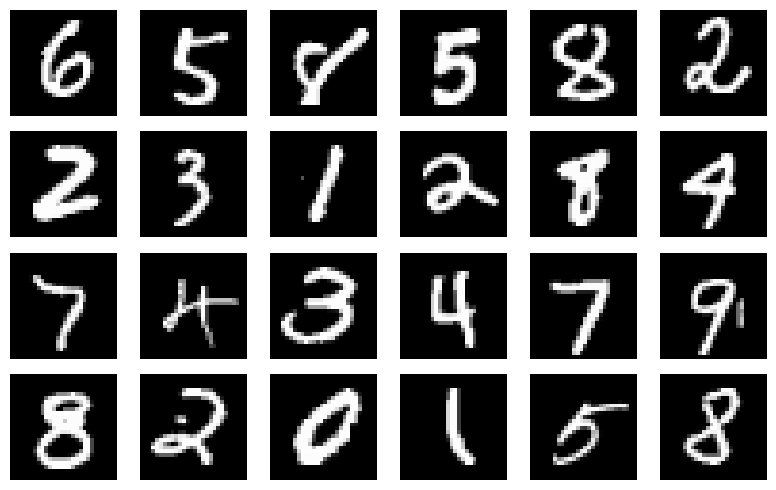

In [4]:
def get_mnist_data(root="./data", train_size=10000, test_size=2000):
    train = tdatasets.MNIST(root=root, train=True, download=True)
    test = tdatasets.MNIST(root=root, train=False, download=True)
    train_indices, _ = train_test_split(
        np.arange(len(train)), train_size=train_size,
        stratify=train.targets.numpy(), random_state=42,
    )
    test_indices, _ = train_test_split(
        np.arange(len(test)), train_size=test_size,
        stratify=test.targets.numpy(), random_state=42,
    )
    X_train = train.data[train_indices].reshape(-1, 784).numpy().astype(np.float32) / 255
    X_test = test.data[test_indices].reshape(-1, 784).numpy().astype(np.float32) / 255
    y_train = train.targets[train_indices].numpy()
    y_test = test.targets[test_indices].numpy()

    fig, axes = plt.subplots(4, 6, figsize=(8, 5))
    for image, ax in zip(X_train[:24], axes.flat):
        ax.imshow(image.reshape(28, 28), cmap="gray")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return X_train, y_train, X_test, y_test

X_mnist, y_mnist, X_mnist_test, y_mnist_test = get_mnist_data()


In [5]:
n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans.fit(X_mnist)

def map_clusters_to_labels(y_true, y_pred, n_clusters):
    mapping = {}
    for cluster in range(n_clusters):
        labels, counts = np.unique(y_true[y_pred == cluster], return_counts=True)
        mapping[cluster] = labels[np.argmax(counts)]
    return mapping

cluster_to_label = map_clusters_to_labels(y_mnist, kmeans.labels_, n_clusters)
kmeans_test_clusters = kmeans.predict(X_mnist_test)
y_pred_labels = np.array([cluster_to_label[cluster] for cluster in kmeans_test_clusters])
print(classification_report(y_mnist_test, y_pred_labels, digits=3, zero_division=0))


              precision    recall  f1-score   support

           0      0.942     0.750     0.835       196
           1      0.608     0.991     0.754       227
           2      0.897     0.631     0.741       206
           3      0.476     0.693     0.565       202
           4      0.394     0.332     0.360       196
           5      0.000     0.000     0.000       178
           6      0.851     0.802     0.826       192
           7      0.483     0.413     0.445       206
           8      0.480     0.564     0.519       195
           9      0.345     0.485     0.403       202

    accuracy                          0.577      2000
   macro avg      0.548     0.566     0.545      2000
weighted avg      0.554     0.577     0.552      2000



In [6]:
silhouette_avg = silhouette_score(X_mnist_test, kmeans_test_clusters)
db_avg = davies_bouldin_score(X_mnist_test, kmeans_test_clusters)

print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies Bouldin Score: {db_avg:.4f}")
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(y_mnist_test, kmeans_test_clusters):.4f}")


Silhouette Score: 0.0587
Davies Bouldin Score: 2.8763
Adjusted Rand Index (ARI): 0.3572


## PCA




<details>
<summary>Схема работы</summary>

1. Обозначим $X$ матрица объекты-признаки, с нулевым средним каждого признака, а $w$ некоторый единичный вектор. Тогда $Xw$ задает величину проекций всех объектов на этот вектор. Разложение на главные компоненты состоит в поиске вектора, проекция которого описывает наибольшую дисперсию:
$$
\max_{w: \|w\|=1}\|Xw\|^2
$$
2. Можно показать, что подходящий вектор равен равен собственному вектору матрицы $X^\top X$, соответствующий максимальному с.з.
3. После нахождения $w$, пространство проецируется на ортогональное дополнение и процесс повторяется.

</details>


### Linear PCA

In [7]:
mnist_train = tdatasets.MNIST(root="./data", train=True, download=True)
mnist_test = tdatasets.MNIST(root="./data", train=False, download=True)
X = np.concatenate([mnist_train.data.numpy(), mnist_test.data.numpy()]).reshape(-1, 784).astype(np.float32) / 255.0
y = np.concatenate([mnist_train.targets.numpy(), mnist_test.targets.numpy()])
print(f"MNIST: {len(X):,} images")


MNIST: 70,000 images


In [8]:
pca = PCA(n_components=2, random_state=42)
started = time.perf_counter()
pca_X = pca.fit_transform(X)
pca_seconds = time.perf_counter() - started
print(f"PCA fit_transform: {pca_seconds:.3f} s")
X_pca_mnist = pca_X
pca.explained_variance_ratio_.sum()

PCA fit_transform: 0.569 s


np.float32(0.1690149)

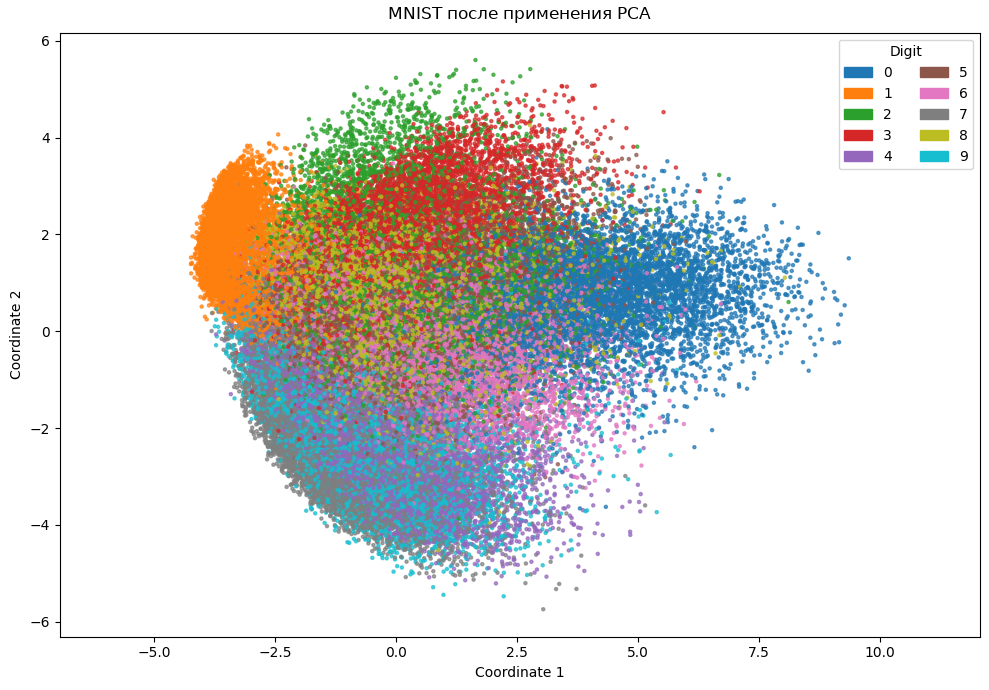

PCA (2D) + K-means
Silhouette Score: 0.3512
Davies Bouldin Score: 0.8415
Adjusted Rand Index (ARI): 0.2342


In [9]:
plot_mnist_embedding(pca_X, y, "MNIST после применения PCA")

pca_kmeans = KMeans(n_clusters=10, random_state=42, n_init=10).fit(pca_X)
pca_clusters = pca_kmeans.labels_
print("PCA (2D) + K-means")
print(f"Silhouette Score: {silhouette_score(pca_X, pca_clusters):.4f}")
print(f"Davies Bouldin Score: {davies_bouldin_score(pca_X, pca_clusters):.4f}")
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(y, pca_clusters):.4f}")


ARI снизился при увеличении Silhouette. Шумная кластеризация хуже согласовывает классы при более выраженной геометрии кластеризации

**Вывод:** Прямое сжатие признаков изображения MNIST с помощью PCA с целью их отображения на плоскости не даёт визуальной кластеризации. Доля объяснимой дисперсии 2 главными компонентами < 17%.

In [10]:
pca = PCA(n_components=0.95)
pca_X = pca.fit_transform(X_mnist)
print(f"PCA components: {pca.n_components_}")

pca_kmeans = KMeans(n_clusters=10, random_state=42, n_init=10).fit(pca_X)
pca_test_X = pca.transform(X_mnist_test)
pca_test_clusters = pca_kmeans.predict(pca_test_X)
pca_cluster_to_label = map_clusters_to_labels(y_mnist, pca_kmeans.labels_, 10)
pca_test_labels = np.array([pca_cluster_to_label[cluster] for cluster in pca_test_clusters])
print("PCA (95% variance) + K-means, MNIST test split")
print(classification_report(y_mnist_test, pca_test_labels, zero_division=0))
print(f"Silhouette Score: {silhouette_score(pca_test_X, pca_test_clusters):.4f}")
print(f"Davies Bouldin Score: {davies_bouldin_score(pca_test_X, pca_test_clusters):.4f}")
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(y_mnist_test, pca_test_clusters):.4f}")


PCA components: 152
PCA (95% variance) + K-means, MNIST test split
              precision    recall  f1-score   support

           0       0.93      0.75      0.83       196
           1       0.61      0.99      0.75       227
           2       0.89      0.63      0.74       206
           3       0.48      0.68      0.56       202
           4       0.39      0.33      0.36       196
           5       0.00      0.00      0.00       178
           6       0.85      0.80      0.82       192
           7       0.49      0.43      0.46       206
           8       0.48      0.57      0.52       195
           9       0.35      0.49      0.40       202

    accuracy                           0.58      2000
   macro avg       0.55      0.57      0.55      2000
weighted avg       0.55      0.58      0.55      2000

Silhouette Score: 0.0651
Davies Bouldin Score: 2.7821
Adjusted Rand Index (ARI): 0.3559


Метрики схожи с K-means на оригинальной размерности MNIST: геометрия (Silhouette) кластеров снова близка к случайной; Распознавание кластеров (ARI) улучшилось относительно 2-х компонент

### Kernel PCA

Когда количество примеров в выборке сильно больше их размерности $N > d$, зачастую, она является линейно-неразделимой. Переход в более высокоразмерное пространтсво $\psi: \mathbb{R}^d \rightarrow \mathbb{R}^N$ при подходящем выборе $\psi$ может сделать исходно нелинейно разделимые группы линейно разделимыми

<img src="src/svm_kernels_intro.png" width="600" style="max-width: 100%; height: auto;">


"Платой" за линейную разделимость является размерность получаемых примеров $\psi(x) \in \mathbb{R}^N$, $N > d$.

["Ядерный трюк" (англ. Kernel Trick) ](https://en.wikipedia.org/wiki/Kernel_method#Mathematics:_the_kernel_trick) позволяет обойти ограничение размерности. Он пременим в том случае, когда метод зависит только от попарных произведений $\langle x_i, x_j \rangle$, а не отдельных значений $x_i$ и $x_j$.

Вместо определения $\psi: \mathbb{R}^d \rightarrow \mathbb{R}^N$, можно определить функцию **ядра**
$$
\mathcal{K}: \mathcal{X}\times\mathcal{X} \rightarrow \mathbb{R}, \quad \mathcal{K}(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle
$$
и центрированную матрицу Грама
$$
K' = K - \mathbf{1_N}K - K\mathbf{1_N} + \mathbf{1_N}K\mathbf{1_N}, \quad K = \|\mathcal{K}(x_i, x_j)\|_{i, j}^N,\,\,\, \mathbf{1_N} \equiv \|1/N\|_{i, j}^N.
$$

Примеры распространённых ядерных функций:

* Константа $\mathcal K_C(x,y)=C\,\,\,\,\,\psi(x)=\sqrt C$, $C\geq0$;
* Линейное $\mathcal K_L(x,y)=x^\top y\,\,\,\,\,\psi(x)=x$;
* Полиномиальное $\mathcal K_{d,c}(x,y)=(x^\top y+c)^d\,\,\,\,\,\psi(x)=\left(\sqrt{\frac{d!}{\alpha!}}\,z(x)^\alpha\right)_{\alpha\in\mathbb N_0^{m+1},\ |\alpha|=d}$, $c\geq0$, $d\in\mathbb N$;
* Радиально-Базисная Функция (РБФ) $\mathcal K_\gamma(x,y)=e^{-\gamma\|x-y\|^2}\,\,\,\,\,\psi(x)=\left(e^{-\gamma\|x\|^2}\sqrt{\frac{(2\gamma)^{|\alpha|}}{\alpha!}}\,x^\alpha\right)_{\alpha\in\mathbb N_0^m}$, $\gamma>0$.

Здесь $x\in\mathbb R^m$, $z(x)=(x_1,\ldots,x_m,\sqrt c)$, $|\alpha|=\sum_j\alpha_j$, $\alpha!=\prod_j\alpha_j!$, $x^\alpha=\prod_jx_j^{\alpha_j}$; аналогично определяется $z^\alpha$.


### Работа Kernel PCA

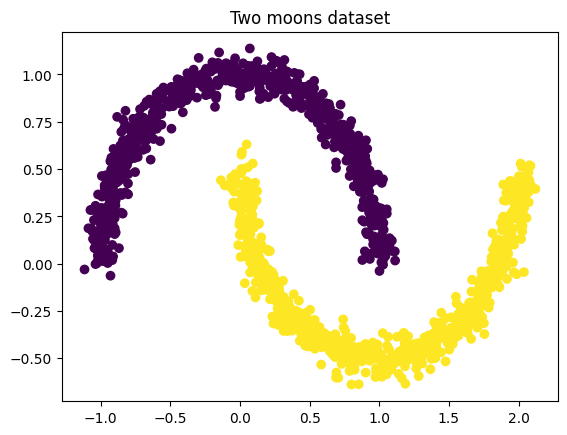

In [12]:
X_moon, y_moon = datasets.make_moons(n_samples=1500, noise=.05, random_state=42)
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis')
plt.title(f"Two moons dataset")
plt.show()

In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_moon)
kmeans_pca = KMeans(n_clusters=2, random_state=42)
clusters_pca = kmeans_pca.fit_predict(X_pca)

По умолчанию RBF: $\mathcal K(x,y)=e^{-\gamma\|x-y\|^2}$, $\gamma=1/\texttt{n\_features}=1/2$ для `X_moon`.


In [14]:
krbfpca = KernelPCA(n_components=2, kernel='rbf')
X_krbfpca = krbfpca.fit_transform(X_moon)
kmeans_krbfpca = KMeans(n_clusters=2, random_state=42)
clusters_krbfpca = kmeans_krbfpca.fit_predict(X_krbfpca)

По умолчанию `poly`: $\mathcal K(x,y)=(\gamma x^\top y+c)^d$, $d=3$ (`degree`), $c=1$ (`coef0`), $\gamma=1/\texttt{n\_features}=1/2$ для `X_moon`.


In [15]:
kppca = KernelPCA(n_components=2, kernel='poly')
X_kppca = kppca.fit_transform(X_moon)
kmeans_kppca = KMeans(n_clusters=2, random_state=42)
clusters_kppca = kmeans_kppca.fit_predict(X_kppca)

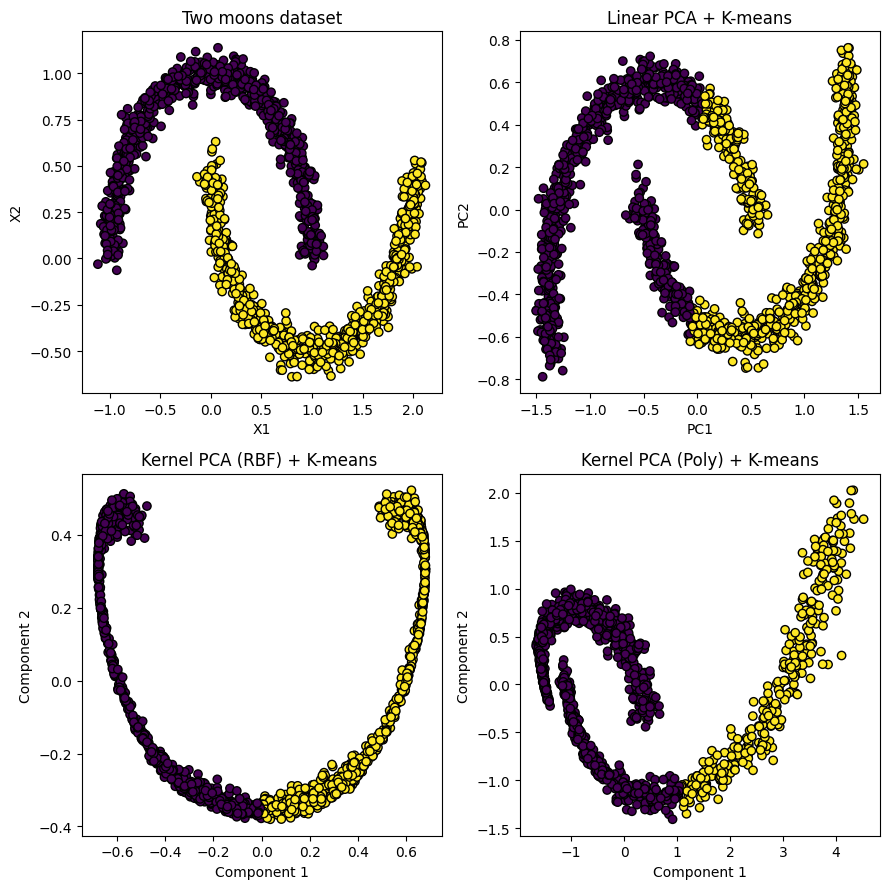

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(9, 9))

ax[0][0].scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis', edgecolor='k')
ax[0][0].set_title("Two moons dataset")
ax[0][0].set_xlabel("X1")
ax[0][0].set_ylabel("X2")

ax[0][1].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_pca, cmap='viridis', edgecolor='k')
ax[0][1].set_title("Linear PCA + K-means")
ax[0][1].set_xlabel("PC1")
ax[0][1].set_ylabel("PC2")

ax[1][0].scatter(X_krbfpca[:, 0], X_krbfpca[:, 1], c=clusters_krbfpca, cmap='viridis', edgecolor='k')
ax[1][0].set_title("Kernel PCA (RBF) + K-means ")
ax[1][0].set_xlabel("Component 1")
ax[1][0].set_ylabel("Component 2")

ax[1][1].scatter(X_kppca[:, 0], X_kppca[:, 1], c=clusters_kppca, cmap='viridis', edgecolor='k')
ax[1][1].set_title("Kernel PCA (Poly) + K-means")
ax[1][1].set_xlabel("Component 1")
ax[1][1].set_ylabel("Component 2")

plt.tight_layout()
plt.show()

## t-SNE


t-Distributed Stochastic Neighbor Embedding (t-SNE) -- [Оффициальная страница автора](https://lvdmaaten.github.io/tsne/)

Реализация в sklearn: [sklearn.manifold.TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)

### SNE

<details>
<summary>Описание SNE</summary>

Имеем выборку $x_1, \ldots, x_n \in \mathbb{R}^D$. Хотим получить выборку $y_1, \ldots, y_n \in \mathbb{R}^d$ меньшей размерности $d < D$ с сохранением кластерной структуры.

1. Зафиксируем $x_i$ и опредлим близость до каждого из объектов $\|x_i - x_j\|^2$.
2. Чем ближе $x_j$ к $x_i$, тем более вероятно мы выберем его соседом. Можно определить соответствующее распределение
$$
p_{j | i} = \dfrac{\exp\{-\|x_i - x_j\|^2/2\sigma_i^2\}}{\sum_{k\neq i}\exp\{-\|x_i - x_k\|^2/2\sigma_i^2\}},
$$
на которое можно смотреть по аналогии SoftMax с температурой $T = 2\sigma_i^2$ или "вероятность выбрать $x_j$ в качестве соседа $x_i$ пропорционально $\mathcal{N}(x_i, \sigma_i^2)$ в точке $x_j$"

3. Энтропия распределения $P_i = (p_{1 | i}, \ldots p_{n | i})$
$$
H(\sigma_i) = -\sum_{j = 1}^n p_{j|i}\log_2 p_{j|i}.
$$
В этом смысле $\sigma_i$ связана с количество "соседей" $x_i$: малые $\sigma_i$ -- низкая энтропия, ярко выделено мало примеров -- мало соседей; большие $\sigma_i$ -- вероятности "сглаживаются" -- больше соседей. Более явную связь даёт перплексия $Perp(P_i(\sigma_i)) = 2^{H(P_i(\sigma_i))}$

4. Аналогично можно определить распределение над $y_1, \ldots y_n$ для $\sigma^2_i = 1/2$
$$
q_{j | i} = \dfrac{\exp\{-\|y_i - y_j\|^2\}}{\sum_{k\neq i}\exp\{-\|y_i - y_k\|^2\}}.
$$

Полагаем $p_{i|i}=q_{i|i}=0$.

**Как поставить оптимизационную задачу?**

5. Ограничением понижения размерности является "сохранение кластерной структуры". В описанных терминах это означает похожесть распределений $P_i$ и $Q_i$.
$$
\mathcal{L} = \sum_{i=1}^n KL(P_i, Q_i) = \sum_{i=1}^n\sum_{j=1}^n p_{j|i}\log\frac{p_{j|i}}{q_{j|i}} \rightarrow \min_{y_1, \ldots y_n}
$$

Соответствующий градиент в точке $y_i$
$$
\dfrac{\partial\mathcal{L}}{\partial y_i} = 2\sum_{j=1}^n(p_{j|i} - q_{j|i} + p_{i|j} - q_{i|j})(y_i - y_j)
$$
* Антиградиент задаёт направление $(y_j - y_i)$, вдоль которого мы обновляем стартовую точку $y_i$. Перенос масштабируется на $(p_{j|i} - q_{j|i} + p_{i|j} - q_{i|j})$.
* Положительный суммарный коэффициент $(p_{j|i} - q_{j|i} + p_{i|j} - q_{i|j})$ даёт притягивающий вклад пары в антиградиент.

</details>


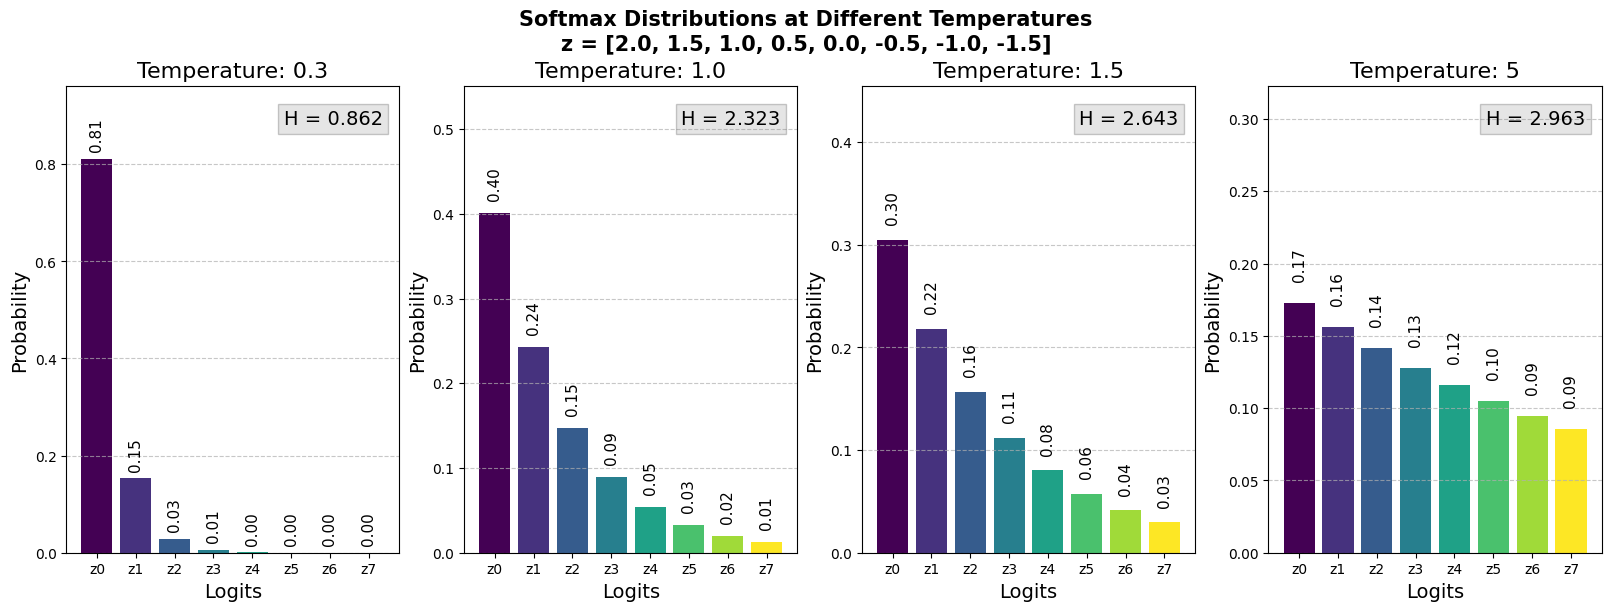

In [17]:
def softmax(x, temperature=1.0):
    x_scaled = x / temperature
    # For numerical stability
    e_x = np.exp(x_scaled - np.max(x_scaled))
    return e_x / e_x.sum()


def softmax_temp_plot():
    plt.figure(figsize=(16, 6), layout='constrained')

    np.random.seed(42)
    z = np.array([2.0, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0, -1.5])

    plt.suptitle(
        f"Softmax Distributions at Different Temperatures\nz = {z.tolist()}",
        fontsize=15, fontweight="bold",
        linespacing=1.25,
    )

    temperatures = [0.3, 1.0, 1.5, 5]

    colors = viridis(np.linspace(0, 1, len(z)))

    for i, temp in enumerate(temperatures):
        ax = plt.subplot(1, 4, i+1)

        probs = softmax(z, temp)
        entropy = -np.sum(probs * np.log2(probs + 1e-10))

        bars = ax.bar(range(len(z)), probs, color=colors)

        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.015,
                    f'{height:.2f}', ha='center', va='bottom',
                    fontsize=11, rotation=90)

        ax.text(0.95, 0.95, f'H = {entropy:.3f}',
                transform=ax.transAxes, ha='right', va='top', bbox=dict(facecolor='gray', alpha=0.2), fontsize=14)

        ax.set_ylim(0, max(probs)+0.15)
        ax.set_xticks(range(len(z)))
        ax.set_xticklabels([f'z{i}' for i in range(len(z))])
        ax.set_xlabel('Logits', fontsize=14)
        ax.set_ylabel('Probability', fontsize=14)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.set_title(f'Temperature: {temp}', fontsize=16)

    plt.show()

softmax_temp_plot()


### Проблема скученности

<details>
<summary>Проблема скученности</summary>

SNE пытается сохранить относительную близость соседей. Для одной точки $i$:
$$
\frac{p_{j|i}}{p_{k|i}}=
\exp\!\left(\frac{\|x_i-x_k\|^2-\|x_i-x_j\|^2}{2\sigma_i^2}\right),\qquad
\frac{q_{j|i}}{q_{k|i}}=
\exp\!\left(\|y_i-y_k\|^2-\|y_i-y_j\|^2\right).
$$

На плоскости трудно одновременно разместить множество близких и умеренно близких соседей с такими же соотношениями вероятностей соседства. Если отодвинуть умеренно близкую точку, её гауссов вес быстро падает: увеличение квадрата расстояния на $\Delta$ умножает вес на $e^{-\Delta}$. Уменьшение $q_{j|i}$ увеличивает $p_{j|i}\log(p_{j|i}/q_{j|i})$. Так возникает скученность.

В t-SNE вес $(1+\|y_i-y_j\|^2)^{-1}$ убывает медленнее: умеренно близкие точки можно разместить дальше друг от друга, сохранив существенный вес их связи.

[Исходная статья, §3.2](https://www.jmlr.org/papers/volume9/vandermaaten08a/vandermaaten08a.pdf).
</details>


In [18]:
"""Conditional SNE with per-point perplexity calibration."""



def _squared_distances(X):
    norms = np.sum(X * X, axis=1)
    return np.maximum(norms[:, None] + norms[None, :] - 2 * X @ X.T, 0.0)


def _row_probabilities(distances, beta, index):
    logits = -beta * distances
    logits[index] = -np.inf
    weights = np.exp(logits - np.max(logits))
    return weights / weights.sum()


def compute_pairwise_affinities(X, perplexity=30):
    distances = _squared_distances(X)
    n = len(X)
    P = np.zeros((n, n))
    target_entropy = np.log(perplexity)
    for i in range(n):
        lower, upper, beta = 0.0, np.inf, 1.0
        for _ in range(60):
            probabilities = _row_probabilities(distances[i], beta, i)
            positive = probabilities > 0
            entropy = -np.sum(probabilities[positive] * np.log(probabilities[positive]))
            if abs(entropy - target_entropy) < 1e-6:
                break
            if entropy > target_entropy:
                lower = beta
                beta = 2 * beta if np.isinf(upper) else (beta + upper) / 2
            else:
                upper = beta
                beta = (beta + lower) / 2
        P[i] = probabilities
    return P


def sne_objective_and_gradient(P, Y):
    distances = _squared_distances(Y)
    logits = -distances
    np.fill_diagonal(logits, -np.inf)
    row_max = np.max(logits, axis=1, keepdims=True)
    log_normalizer = row_max + np.log(np.exp(logits - row_max).sum(axis=1, keepdims=True))
    log_Q = logits - log_normalizer
    Q = np.exp(log_Q)
    positive = P > 0
    loss = np.sum(P[positive] * (np.log(P[positive]) - log_Q[positive]))
    residual = P - Q
    coefficients = residual + residual.T
    gradient = 2 * (coefficients.sum(axis=1, keepdims=True) * Y - coefficients @ Y)
    return loss, gradient


def sne(X, n_components=2, perplexity=30, learning_rate=0.1, n_iter=500, random_state=42):
    P = compute_pairwise_affinities(X, perplexity)
    Y = np.random.default_rng(random_state).normal(scale=1e-4, size=(len(X), n_components))
    for _ in range(n_iter):
        _, gradient = sne_objective_and_gradient(P, Y)
        Y -= learning_rate * gradient
    return Y


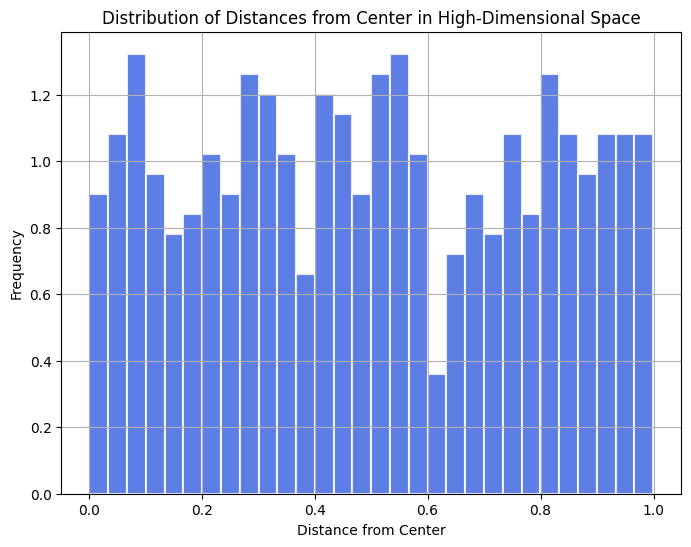

In [19]:
# Генерация точек в высокомерном пространстве
np.random.seed(42)
n_points = 500
high_dim = 10
radius = 1.0

# Случайные точки внутри гиперсферы высокой размерности
points_high_dim = np.random.normal(size=(n_points, high_dim))
points_high_dim /= np.linalg.norm(points_high_dim, axis=1, keepdims=True)
points_high_dim *= np.random.uniform(0, radius, size=(n_points, 1))

# Расстояния от центра в высокомерном пространстве
distances_from_center = np.linalg.norm(points_high_dim, axis=1)

# Визуализация распределения расстояний в высокомерном пространстве
plt.figure(figsize=(8, 6))
plt.hist(
    distances_from_center,
    bins=30,
    color='royalblue',
    alpha=0.85,
    edgecolor='white',
    linewidth=1.5,
    density=True
)
plt.title("Distribution of Distances from Center in High-Dimensional Space")
plt.xlabel("Distance from Center")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

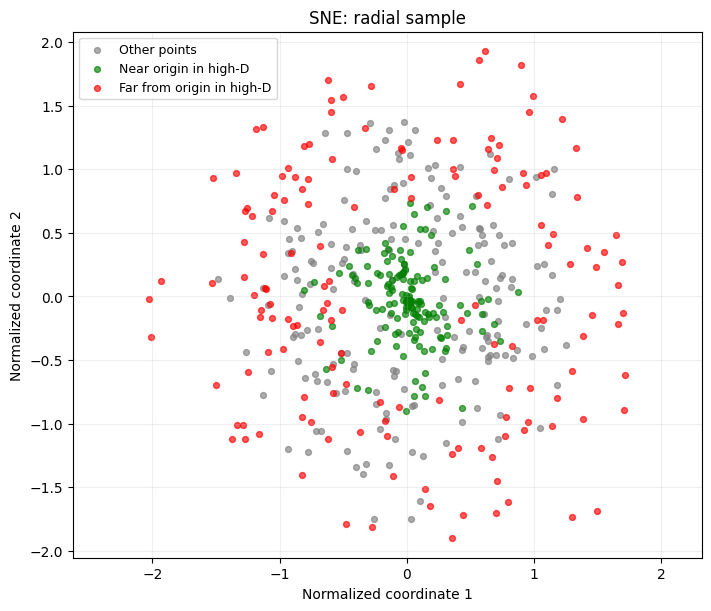

In [20]:
sne_projection = sne(
    points_high_dim,
    n_components=2,
    perplexity=30,
    learning_rate=0.1,
    n_iter=500,
    random_state=42,
)


def plot_radial_map(ax, embedding, title):
    centered = embedding - embedding.mean(axis=0)
    rms_radius = np.sqrt(np.mean(np.sum(centered**2, axis=1)))
    normalized = centered / rms_radius
    near = distances_from_center < 0.3 * radius
    far = distances_from_center > 0.7 * radius
    for mask, color, label in [
        (~near & ~far, 'gray', 'Other points'),
        (near, 'green', 'Near origin in high-D'),
        (far, 'red', 'Far from origin in high-D'),
    ]:
        ax.scatter(normalized[mask, 0], normalized[mask, 1],
                   s=18, alpha=0.65, color=color, label=label)
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel('Normalized coordinate 1')
    ax.set_ylabel('Normalized coordinate 2')
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)


fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
plot_radial_map(ax, sne_projection, 'SNE: radial sample')
plt.show()


### t-SNE

<details>
<summary>Описание t-SNE</summary>

Используем совместные симметризованные вероятности
$$
p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n},\qquad p_{ii}=q_{ii}=0.
$$

Одномерное стандартное $t_\nu$-распределение Стьюдента с $\nu>0$ степенями свободы имеет плотность
$$
f_\nu(z)=\frac{\Gamma((\nu+1)/2)}{\sqrt{\nu\pi}\,\Gamma(\nu/2)}
\left(1+\frac{z^2}{\nu}\right)^{-(\nu+1)/2},\qquad z\in\mathbb R.
$$
При $\nu=1$ получаем $f_1(z)=1/[\pi(1+z^2)]$. Для пары точек используем вес
$w_{ij}=\pi f_1(\|y_i-y_j\|)=(1+\|y_i-y_j\|^2)^{-1}$ и нормируем его по всем парам:
$$
q_{ij} = \dfrac{(1 + \|y_i - y_j\|^2)^{-1}}{\sum_{k\neq l}(1 + \|y_k - y_l\|^2)^{-1}}
$$
Минимизируем
$$
\mathcal L=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$
Соответствующий градиент по $y_i$
$$
\dfrac{\partial\mathcal{L}}{\partial y_i} = 4\sum_{j=1}^n\dfrac{(p_{ij} - q_{ij})(y_i - y_j)}{1 + \|y_i - y_j\|^2}
$$


В градиенте появляется множитель $(1+\|y_i-y_j\|^2)^{-1}$:

* Для близких точек $\|y_i-y_j\|^2\approx0$ множитель близок к единице.
* Для далёких точек $\|y_i-y_j\|^2\gg0$ он уменьшает вклад при одинаковом $p_{ij}-q_{ij}$.
* Вместе с тяжёлыми хвостами нового $q_{ij}$ это ослабляет проблему скученности. Меняется форма хвоста, а не только ширина гауссова распределения.

[Лекция, слайд 30](Slides_Lecture_ML.pdf#page=39).

</details>


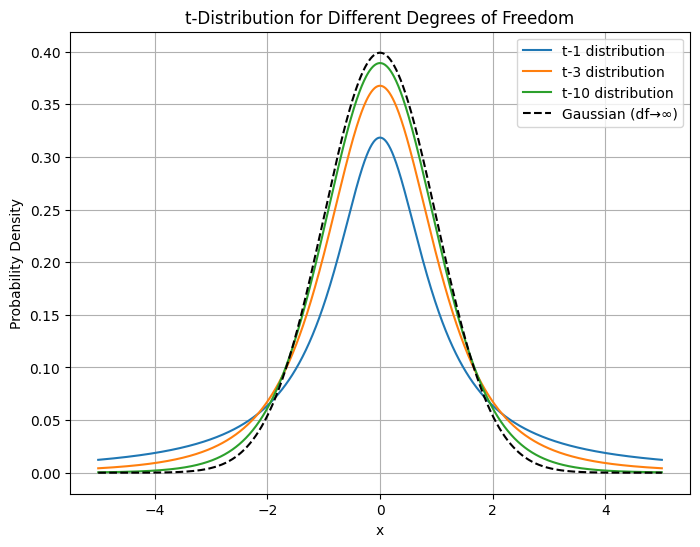

In [21]:
x = np.linspace(-5, 5, 1000)
t_values = [1, 3, 10]
plt.figure(figsize=(8, 6))
for df in t_values:
    plt.plot(x, t.pdf(x, df), label=f"t-{df} distribution")
plt.plot(x, norm.pdf(x, 0, 1), 'k--', label="Gaussian (df→∞)")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title("t-Distribution for Different Degrees of Freedom")
plt.legend()
plt.grid()
plt.show()

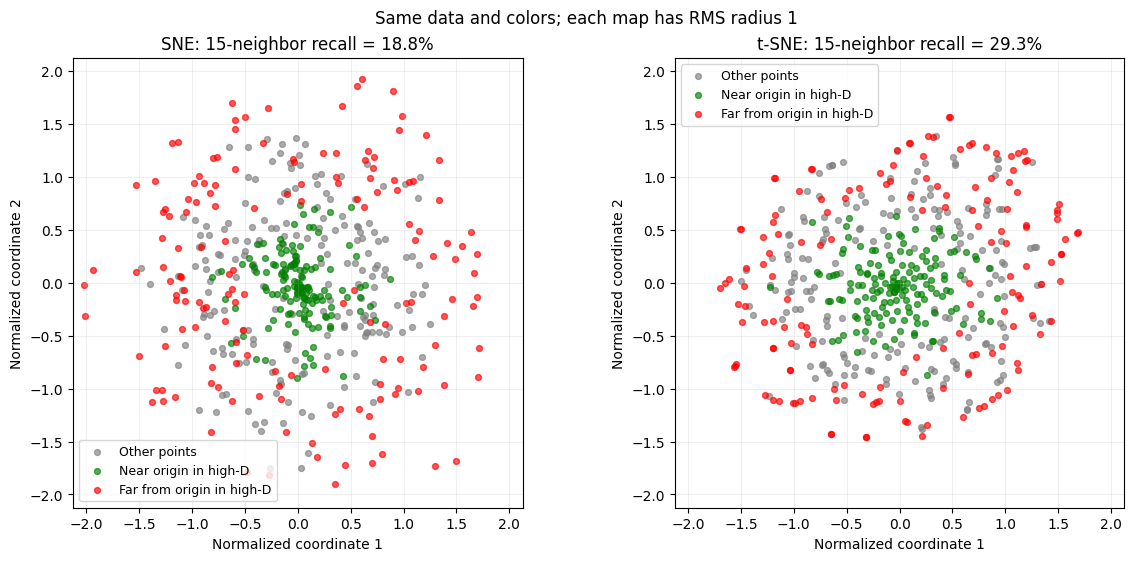

In [22]:
tsne = TSNE(
    n_components=2, random_state=42, perplexity=30,
    init='random', learning_rate='auto', n_jobs=1,
)
tsne_projection = tsne.fit_transform(points_high_dim)


def neighbor_recall(X, embedding, k=15):
    source_distances = _squared_distances(X)
    target_distances = _squared_distances(embedding)
    np.fill_diagonal(source_distances, np.inf)
    np.fill_diagonal(target_distances, np.inf)
    source_neighbors = np.argsort(source_distances, axis=1)[:, :k]
    target_neighbors = np.argsort(target_distances, axis=1)[:, :k]
    return np.mean([
        len(set(source).intersection(target)) / k
        for source, target in zip(source_neighbors, target_neighbors)
    ])


fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, name, embedding in zip(
    axes, ['SNE', 't-SNE'], [sne_projection, tsne_projection],
):
    recall = neighbor_recall(points_high_dim, embedding)
    plot_radial_map(ax, embedding, f'{name}: 15-neighbor recall = {recall:.1%}')
all_maps = []
for embedding in [sne_projection, tsne_projection]:
    centered = embedding - embedding.mean(axis=0)
    all_maps.append(centered / np.sqrt(np.mean(np.sum(centered**2, axis=1))))
limits = np.max(np.abs(np.concatenate(all_maps))) * 1.05
for ax in axes:
    ax.set_xlim(-limits, limits)
    ax.set_ylim(-limits, limits)
    ax.set_aspect('equal', adjustable='box')
fig.suptitle('Same data and colors; each map has RMS radius 1')
plt.show()


### t-SNE + MNIST



#### Сложность вычисления

Сложность одной итерации точного градиента SNE и t-SNE $\mathcal{O}(n^2d)$, разовая сложность вычисления исходных попарных расстояний $\mathcal O(n^2D)$ -- это много для реальных наборов данных. [Ускорения](https://arborjs.org/docs/barnes-hut) t-SNE дают $\mathcal{O}(n\log n)$ на итерацию при фиксированном $d$. Но даже это вычислительно-затратно для реальных высокоразмерных данных с большим количеством примеров. Чтобы уменьшить зависимость по D, рекомендуется вначале снизить размерность с помощью PCA.


In [23]:
%%time
X_tsne_mnist, y_tsne_mnist = X, y
pca = PCA(n_components=30, random_state=42)
pca_X = pca.fit_transform(X_tsne_mnist)
pca.explained_variance_ratio_.sum()


CPU times: user 606 ms, sys: 0 ns, total: 606 ms
Wall time: 605 ms


np.float32(0.7316251)

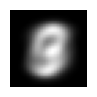

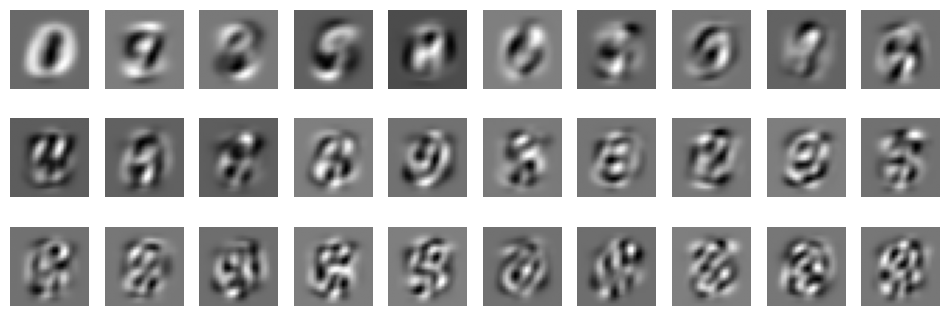

In [24]:
plt.figure(figsize=(1, 1))
plt.imshow(pca.mean_.reshape((28, 28)), cmap='gray')
plt.axis('off')
plt.show()

plt.figure(figsize=(12, 4))
for i in range(30):
    plt.subplot(3, 10, i + 1)
    plt.imshow(pca.components_[i].reshape((28, 28)), cmap='gray')
    plt.axis('off')


In [25]:
tsne = TSNE(n_components=2, perplexity=40, random_state=42, n_jobs=1)
started = time.perf_counter()
tsne_X = tsne.fit_transform(pca_X)
tsne_seconds = time.perf_counter() - started
print(f"t-SNE fit_transform: {tsne_seconds:.3f} s ({tsne_seconds / 60:.2f} min)")


t-SNE fit_transform: 728.118 s (12.14 min)


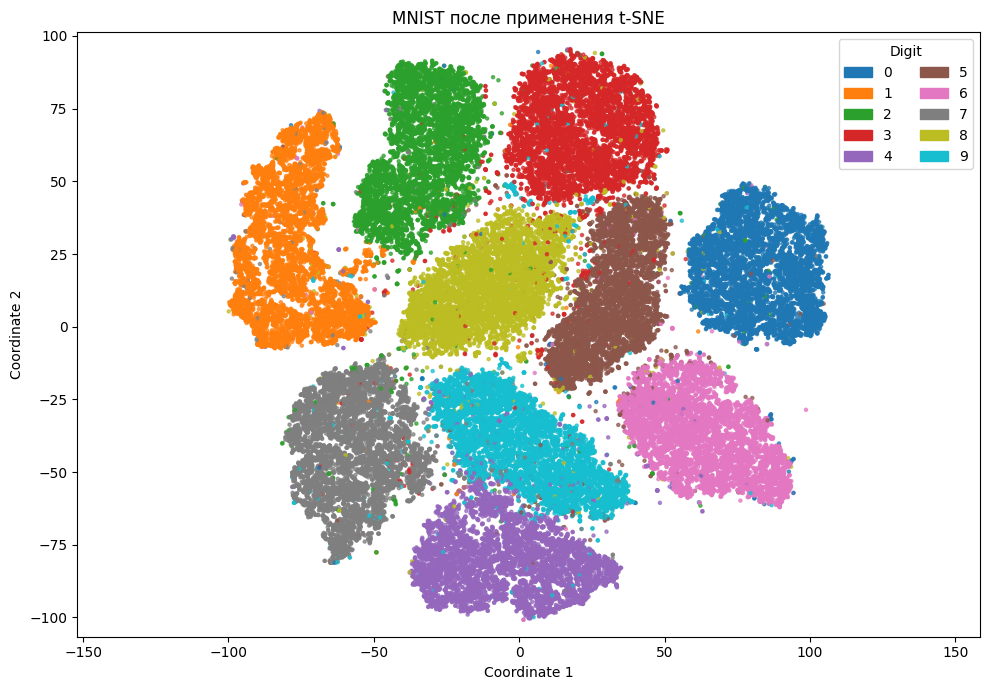

In [26]:
plot_mnist_embedding(tsne_X, y_tsne_mnist, "MNIST после применения t-SNE")


In [27]:
n_clusters = 10  # Since MNIST has 10 digits (0-9)
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans.fit(tsne_X)

cluster_to_label = map_clusters_to_labels(y_tsne_mnist, kmeans.labels_, n_clusters)

y_pred_labels = np.array([cluster_to_label[cluster] for cluster in kmeans.labels_])

print("\nt-SNE + K-means")
print(classification_report(y_tsne_mnist, y_pred_labels))



t-SNE + K-means
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6903
           1       0.94      0.88      0.91      7877
           2       0.85      0.88      0.86      6990
           3       0.96      0.95      0.95      7141
           4       0.90      0.96      0.93      6824
           5       0.85      0.87      0.86      6313
           6       0.93      0.99      0.96      6876
           7       0.97      0.97      0.97      7293
           8       0.91      0.85      0.88      6825
           9       0.85      0.82      0.84      6958

    accuracy                           0.92     70000
   macro avg       0.91      0.92      0.91     70000
weighted avg       0.92      0.92      0.92     70000



In [28]:
%%time
ri_score = rand_score(y_tsne_mnist, kmeans.labels_)
ari_score = adjusted_rand_score(y_tsne_mnist, kmeans.labels_)
print(f"Rand Index (RI): {ri_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")


Rand Index (RI): 0.9695
Adjusted Rand Index (ARI): 0.8309
CPU times: user 10.9 ms, sys: 101 μs, total: 11 ms
Wall time: 9.71 ms


In [29]:
%%time
silhouette_avg = silhouette_score(tsne_X, kmeans.labels_)
db_avg = davies_bouldin_score(tsne_X, kmeans.labels_)

print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies Bouldin Score: {db_avg:.4f}")


Silhouette Score: 0.4441
Davies Bouldin Score: 0.7458
CPU times: user 27.2 s, sys: 6.08 s, total: 33.3 s
Wall time: 33.3 s


#### Кластерная структура

t-SNE не адресует к глобальной структуре данных, потому что он не пытается её описать. "Похожесть кластерной структуры" определяется в терминах близости входного $P$ и моделируемого $Q$ распределений:
$$
\mathcal{L} = KL(P,Q) = \sum_{i\ne j} p_{ij}\log\frac{p_{ij}}{q_{ij}} \rightarrow \min_{y_1, \ldots y_n}
$$

Если мы возьмём 2 примера $i$, $j$ из разных, удалённых друг от друга групп, то $p_{ij}$ обычно мало: $p_{ij}$ -- степень соседства примеров.

При фиксированном $q_{ij}>0$ слагаемое $p_{ij}\log(p_{ij}/q_{ij})\to0$ при $p_{ij}\to0$. Но $q_{ij}$ нормированы совместно: изменение расстояния одной пары меняет знаменатель и вероятности остальных пар. Поэтому расстояния между островами не калиброваны как мера различия классов.


## UMAP

1. [Документация](https://umap-learn.readthedocs.io/en/latest/index.html)
2. [Understanding UMAP](https://pair-code.github.io/understanding-umap/)
3. [A deeper dive into UMAP theory](https://pair-code.github.io/understanding-umap/supplement.html)
4. Оригинальная статья 🤯: https://arxiv.org/pdf/1802.03426
5. Один из наиболее современных методов понижения размерности.
6. [Статья](https://arxiv.org/pdf/2501.07729) от 2025 года
    * Использование Автоэнкодера для получения сжатых информативных признаковых описаний
    * UMAP для последующего сжатия размерности
    * K-mean/DBSCAN для финальной кластеризации.
7. [MAPLE: Self-Supervised Learning-Enhanced Nonlinear Dimensionality Reduction for Visual Analysis (2026)](https://arxiv.org/abs/2601.20173), [IEEE VIS 2026 / TVCG](https://www.ieeevis.org/year/2026/program/paper/ef18ee6e-f372-4cb2-a57b-6dfc58a569f0/).
    * Самообучаемое представление улучшает граф соседей; построение карты использует подход UMAP.


### Мотивация



#### Структура кластеров

Рассмотрим пример с [Fashion MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist)

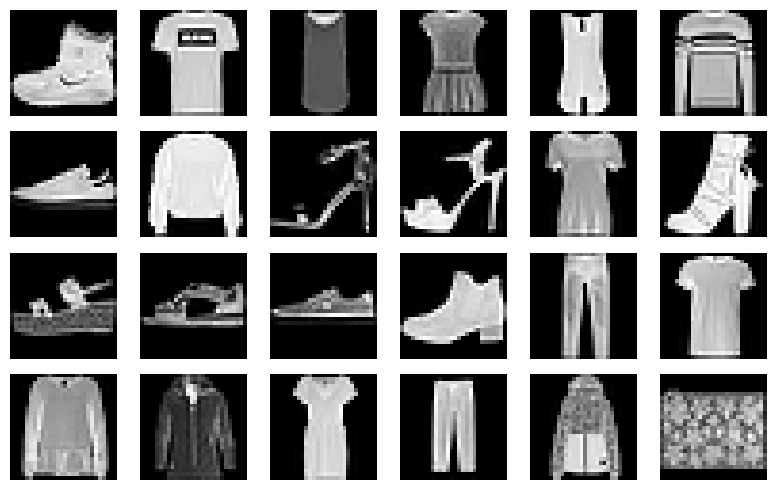

In [30]:
fashion_preview = tdatasets.FashionMNIST(root="./data", train=True, download=True)
fig, axes = plt.subplots(4, 6, figsize=(8, 5))
for image, ax in zip(fashion_preview.data[:24], axes.flat):
    ax.imshow(image, cmap="gray")
    ax.axis("off")
plt.tight_layout()
plt.show()


* Опыт подсказывает нам, что футболка ближе к рубашкам и платью (по семантике), а сандали к ботинкам.
* Но что ближе: Футболка к сумке или ботинок к сумке?

t-SNE [не адресует](https://pair-code.github.io/understanding-umap/) к глобальной структуре данных.



#### Вычислительная сложность

* В UMAP вычисления включают поиск соседей и оптимизацию положения точек графа.
* Существует множество эффективных масштабируемых алгоритмов поиска соседей ([NN-descent](https://www.cs.princeton.edu/cass/papers/www11.pdf), [Annoy](https://github.com/spotify/annoy), [FAISS](https://arxiv.org/pdf/1702.08734)).
* Для этапа приближённого поиска соседей авторы приводят эмпирическую оценку $\mathcal{O}(n^{1.14})$, $n$ -- число примеров; это не общая гарантия сложности UMAP.


In [31]:
X_mnist_train = X
labels_mnist_train = y


UMAP fit_transform: 55.747 s (0.93 min)


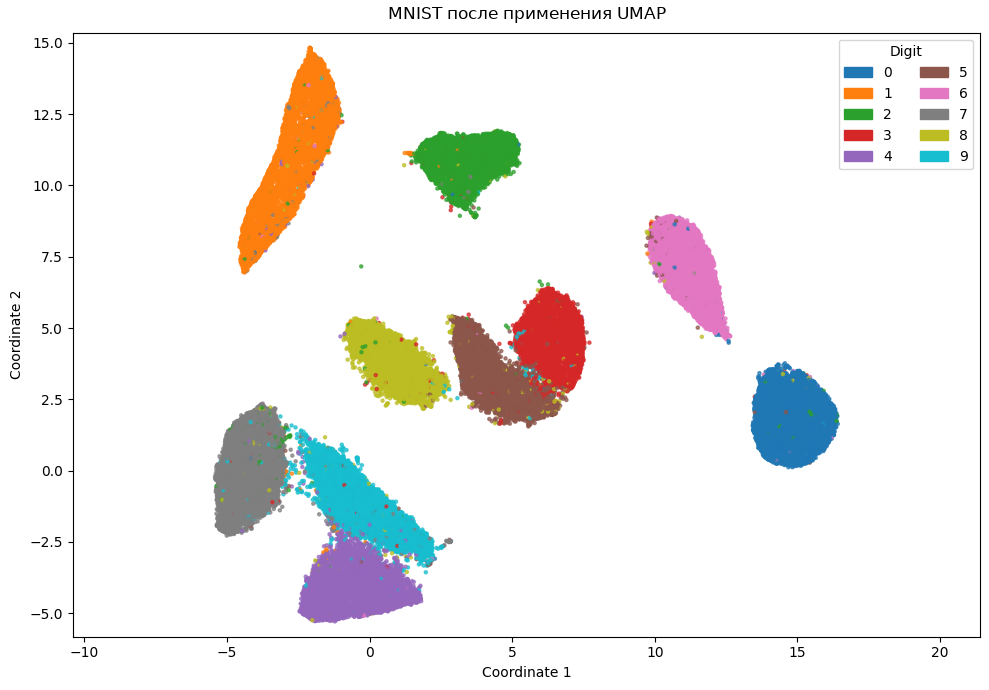

In [32]:
model = UMAP(n_components=2, random_state=42, n_jobs=1)
started = time.perf_counter()
X_umap_train = model.fit_transform(X_mnist_train)
umap_seconds = time.perf_counter() - started
print(f"UMAP fit_transform: {umap_seconds:.3f} s ({umap_seconds / 60:.2f} min)")
plot_mnist_embedding(X_umap_train, labels_mnist_train, "MNIST после применения UMAP")


Обратите внимание, в отличие от t-SNE мы также обучались на оригинальной размерности MNIST.

Самое сложное в методах понижения размерности -- описать **структуру (многообразие)** высокоразмерных данных.

### M -- Manifold

In [33]:
Video(filename="src/PoleM.mp4", embed=False, width=640)


Но что же такое [многообразие](https://en.wikipedia.org/wiki/Manifold)?

<img src="src/NXLlV.png" width="800" style="max-width: 100%; height: auto;">


Для анализа данных гораздо понятнее воспринимать многообразие как форму, которую принимают точки в d-мерном пространстве.

Пример с окружностью

In [35]:
Video(filename="src/AnimateManifoldWithoutAxes.mp4", embed=False, width=640)


Пример MNIST

In [36]:
Video(filename="src/MnistRule.mp4", embed=False, width=640)


Окружность можно покрыть перекрывающимися дугами. На каждой дуге положение точки задаётся одной координатой. Дуга вместе с выбранной координатой — **карта**, а набор таких карт, покрывающий всю окружность, — **атлас**.


<img src="src/Circle_with_overlapping_manifold_charts.png" width="700" style="max-width: 100%; height: auto;">


Окружность — одномерное многообразие в $\mathbb R^2$: на каждой достаточно малой дуге хватает одной координаты.


#### Как определять характеристики поверхности?

Треугольники! (полигональное покрытие)

Пример с MNIST показал, что явно задать многообразие, на котором лежат данные, обычно трудно. Но это и не требуется. Достаточно обращаться к локальным особенностям в данных для описания глобальной структуры.


<img src="src/mesh_comparison.png" width="1000" style="max-width: 100%; height: auto;">


Обощением являются симплексы

<img src="src/O6xtg.png" width="800" style="max-width: 100%; height: auto;">


#### Как строить полигональные покрытия?

Такая процедура называется фильтрацией (filtration)

<img src="src/filtration_pone_0213679_fig3.png" width="1000" style="max-width: 100%; height: auto;">


Иллюстрация имеет следующую логику: если область внутри ребер закрашена -- это двумерный симплекс. На рисунке (С) у нас 2 двумерных симплекса, 4 одномерных и один 0-мерный.

Как видно из (С), Покрытия можно собирать разными размерностями симплексов

<img src="src/simplices_s41524_2021_493_fig4.png" width="700" style="max-width: 100%; height: auto;">


Но как определить, симплексом какой размерности "покрывать" $k$ точек?

#### Симплексные комплексы (Simplicial Complexes)

##### Теорема Нерва

Основная "математическая обоснованность" UMAP лежит в [теореме Нерва](https://en.wikipedia.org/wiki/Nerve_complex).

Давайте вернёмся к определению многообразия $\mathcal{M}$

<img src="src/NXLlV.png" width="800" style="max-width: 100%; height: auto;">


Грубо говоря, многообразие описывается некоторыми "картами" (charts) $\{U_\alpha\}_\alpha$ (см. пример с окружностью).

Давайте выделим покрывающее многообразие семейство $C = \{U_i\}_{i\in I} \subset \{U_\alpha\}_\alpha$.

Тогда, в некотором смысле (гомотопично) объединение $\bigcup C$
эквивалентно $\mathcal{M}$.

Определим *нерв* семейства $C$
$$
N(C) := \left\{J \subseteq I \,:\, \bigcap_{j\in J} U_j \neq ∅, \quad J \,\,\text{is finite set}\right\}
$$
Т.е. это все конечные подмножества, в которых пересечение не пусто.

Мы вольны определять, как задавать различные $C$. **Теорема Нерва** даёт *достаточные* условия на $C$, гарантирующие, что $N(C)$ эквивалентно (гомотопично) многообразию $\mathcal{M}$.

Интуитивно, это следует из того, что многообразие $\mathcal{M}$ локально воспроизводит Евклидово пространство $\mathbb{R}^d$. Если мы "корректно" зададим $C$, то $N(C)$ сможет "комбинаторно" (конечными множествами) в достаточно масштабе описать Евклидово пространство и "покрыть" многообразие.


**Причем здесь симплексы?**

##### Čech Simplicial Complex

Данные можно представить как облако точек $x_i \in X$. Это облако заведомо-конечно, мы можем выбрать покрытие $C_r = \{\mathcal{B}(x_i, r) | x_i \in X\}$. Тогда нерв $C_r$:
$$
N(C_r) := \left\{J \subseteq I \,:\, \bigcap_{j\in J} \mathcal{B}(x_j, r) \neq ∅, \quad J \,\,\text{is finite set}\right\}.
$$

Данное покрытие называется **Čech Cover** и соответствующий нерв **Čech Nerve.** Для Čech Nerve выполнима Теорема Нерва, т.е. нерв гомотопически эквивалентен объединению шаров $\bigcup_{x_i\in X}\mathcal{B}(x_i,r)$.

Из определения нерва $C_r$:
* $|J| = 1 \Rightarrow \cap_{j\in J} \mathcal{B}(x_j, r) = \mathcal{B}(x_{j_0}, r) \neq ∅$. Точка всегда входит в нерв. *Это 0-симплекс*
* $|J| = 2,\ J \in N(C_r) ⇔ \mathcal{B}(x_{j_0}, r) \cap \mathcal{B}(x_{j_1}, r) \neq ∅$. Тогда $x_{j_0}$ и $x_{j_1}$ -- *Это 1-симплекс*.
* В общем случае $\{x_0, \ldots x_k\}$ -- k-симплекс $⇔ \cap_{i=0}^k \mathcal{B}(x_i, r) \neq ∅$.

Мы построили **Čech Simplicial Complex!** Основное правило, по которому строится высокоразмерный граф с математическим обоснованием приближения многообразия 🤗.

Давайте снова взглянем на процедуру фильтрации

<img src="src/filtration_pone_0213679_fig3.png" width="1000" style="max-width: 100%; height: auto;">


Согласитесь, эти кружочки теперь выглядят осмысленнее.

**Почему именно кружочки (Čech Simplicial Complex) ?**

Разве покрытие $C_r = \{\mathcal{B}(x_i, r) | x_i \in X\}$ единственное, которое удовлетворяет теореме Нерва?

Конечно, нет:


* [Leray Nerve](https://en.wikipedia.org/wiki/Nerve_complex#Leray's_nerve_theorem);
* [Borsuk Nerve](https://en.wikipedia.org/wiki/Nerve_complex#Borsuk's_nerve_theorem);
* [Homological Nerve](https://en.wikipedia.org/wiki/Nerve_complex#Homological_nerve_theorem).

Тогда почему именно Čech Nerve?

Все дело в структуре нашего многообразия $x_i \in X \subset \mathcal{M}$ -- облако точек высокой размерности, которых много. UMAP во многом адресует к вычислительной эффективности t-SNE, поэтому покрытие должно быть вычислительно-эффективным.

Čech Nerve строится по общим пересечениям шаров вокруг объектов

##### Čech Implementation

<details>
<summary>Подробнее: реализация Čech</summary>

Имплементируем построение симплексов по Čech Nerve до 3-симплекса

1-симплекс -- простая проверка расстояний.

2-симплекс -- есть много способов определить пересечение 3-х окружностей. Однако воспользуемся тем, что имеет обобщение на случай k-симплекса

<img src="src/G8M1k.jpg" width="600">

У кругов с центрами $A$, $B$, $C$ и радиусом $r$ есть общая точка $O$, если $\max_{X\in\{A, B, C\}}\|O - X\| \leqslant r$.

Если пересечение кругов -- область $\mathcal{O}$, то для пересечения кругов достаточно, чтобы $\min_{O\in\mathbb{R}^2}\max_{X\in\{A, B, C\}}\|O - X\| \leqslant r$.

Минимум такой задачи находится в центре "минимального покрывающего круга" (minimum enclosing circle) -- это видно и из диаграммы и верно в случае большего числа кругов.

Для остроугольного треугольника $ABC$ минимальный круг совпадает с описанной окружностью:
$$
R = \dfrac{d_{AB}\cdot d_{BC} \cdot d_{AC}}{4S},
$$
где площадь $S$ можно определить по формуле Герона.
Для прямоугольного и тупоугольного треугольника минимальный круг имеет наибольшую сторону диаметром.

Таким образом, для проверки что $\{x_0, \ldots x_k\}$ -- k-симплекс $⇔ \cap_{i=0}^k \mathcal{B}(x_i, r) \neq ∅$ нам достаточно уметь строить минимальную покрывающую окружность для $k+1$ точек.

Это можно сделать с помощью [Welzl’s algorithm](https://people.inf.ethz.ch/emo/PublFiles/SmallEnclDisk_LNCS555_91.pdf).

Наконец, Čech-Complex implementation!

Проводим только до 3-симплекса для удобства визуализации.

</details>


In [44]:
def plot_points(points, figsize=(8, 5), point_color='k', point_size=50, background_color='#f7f7f7'):
    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(points[:, 0], points[:, 1], c=point_color, s=point_size, zorder=5, label='0-simplex')
    ax.grid(
        True,
        linestyle='--',
        linewidth=0.6,
        alpha=0.7
    )
    ax.set_facecolor(background_color)
    return fig, ax

def add_circles(ax, centers, radius, color='C0', alpha=0.3):
    for center in centers:
        circle = plt.Circle(center, radius, facecolor='none', alpha=alpha, edgecolor=color)
        ax.add_patch(circle)

def first_order_simplex(p, q):
    center = (p + q) / 2
    return center, np.linalg.norm(p - center)

def second_order_simplex(p, q, r):
    d_pq = np.linalg.norm(p - q)
    d_pr = np.linalg.norm(p - r)
    d_qr = np.linalg.norm(q - r)
    a, b, c = d_qr, d_pr, d_pq
    s = 0.5 * (a + b + c)
    A = math.sqrt(max(s * (s - a) * (s - b) * (s - c), 0.0))

    if A == 0 or (c**2 > a**2 + b**2) or (b**2 > a**2 + c**2) or (a**2 > b**2 + c**2):
        pts = {d_pq: (p, q), d_pr: (p, r), d_qr: (q, r)}
        d_max = max(pts)
        u, v = pts[d_max]
        center = (u + v) / 2
        return center, d_max / 2

    det = (q - p)[0] * (r - p)[1] - (q - p)[1] * (r - p)[0]
    ux = ((np.dot(q - p, q - p) * (r - p)[1] - np.dot(r - p, r - p) * (q - p)[1]) / (2 * det))
    uy = ((np.dot(r - p, r - p) * (q - p)[0] - np.dot(q - p, q - p) * (r - p)[0]) / (2 * det))
    center = p + np.array([ux, uy])
    return center, np.linalg.norm(p - center)

def _ball_from(R):
    R = list(R)
    if not R:
        return np.zeros(2), 0.0
    if len(R) == 1:
        # 0-simplex
        return np.array(R[0]), 0.0
    if len(R) == 2:
        # 1-simplex
        return first_order_simplex(*R)
    if len(R) == 3:
        # 2-simplex
        return second_order_simplex(*R)
    P = np.vstack(R)
    A = P[1:] - P[0]
    b = 0.5 * (np.sum(P[1:]**2, axis=1) - np.sum(P[0]**2))
    # k-simplex -- solve SLE
    center = np.linalg.lstsq(A, b, rcond=None)[0]
    radius = np.linalg.norm(P[0] - center)
    return center, radius

def _welzl(P, R):
    if not P or len(R) == P[0].shape[0] + 1:
        return _ball_from(R)
    p = P.pop()
    center, rad = _welzl(P, R)
    if np.linalg.norm(p - center) <= rad + 1e-8:
        P.append(p)
        return center, rad
    R.append(p)
    center, rad = _welzl(P, R)
    R.pop()
    P.append(p)
    return center, rad

def k_order_simplex(points):
    P = list(points.copy())
    np.random.shuffle(P)
    center, r = _welzl(P, [])
    return center, r

def cech_complex(points, r):
    n = len(points)
    # Edges (1-simplex)
    edges = []
    for i, j in itertools.combinations(range(n), 2):
        _, R = first_order_simplex(points[i], points[j])
        if R <= r:
            edges.append((i, j))

    # Triangles (2-simplex)
    triangles = []
    for i, j, k in itertools.combinations(range(n), 3):
        _, R = second_order_simplex(points[i], points[j], points[k])
        if R <= r:
            triangles.append((i, j, k))

    # Tetrahedrons (3-simplex)
    tetras = []
    for i, j, k, l in itertools.combinations(range(n), 4):
        _, R = k_order_simplex(np.array([points[i], points[j], points[k], points[l]]))
        if R <= r:
            tetras.append((i, j, k, l))
    return {'edges': edges, 'triangles': triangles, 'tetras': tetras}

def compute_point_dims(n_points, complex_dict):
    dims = [0]*n_points
    for i,j       in complex_dict['edges']:     dims[i]=max(dims[i],1); dims[j]=max(dims[j],1)
    for i,j,k     in complex_dict['triangles']: dims[i]=max(dims[i],2); dims[j]=max(dims[j],2); dims[k]=max(dims[k],2)
    for i,j,k,l   in complex_dict['tetras']:    dims[i]=max(dims[i],3); dims[j]=max(dims[j],3); dims[k]=max(dims[k],3); dims[l]=max(dims[l],3)
    return dims

def plot_complex_by_point(fig, ax, points, complex_dict, r_circle):
    dims = compute_point_dims(len(points), complex_dict)

    # always draw radius circles (outline) for all points
    for idx in range(len(points)):
        circ = plt.Circle(points[idx], r_circle,
                      facecolor='none', edgecolor='k', linestyle='--', linewidth=1.2,
                      zorder=4)
        ax.add_patch(circ)

    simplices = []
    # 0‑simplices → filled circles
    for idx, d in enumerate(dims):
        if d == 0:
            if '0' not in simplices:
                label = '0-simplex'
                simplices.append('0')
            else:
                label = None
            ax.add_patch(plt.Circle(points[idx], r_circle,
                                 facecolor='C5', edgecolor='k', alpha=0.4, zorder=6, label=label))

    # 1‑simplices → solid edges
    for i,j in complex_dict['edges']:
        if not any({i, j}.issubset(face) for face in complex_dict['triangles'] + complex_dict['tetras']):
            if '1' not in simplices:
                label = '1-simplex'
                simplices.append('1')
            else:
                label = None
            ax.plot(*zip(points[i], points[j]),
                    color='C2', linewidth=2, zorder=5, label=label)

    # 2‑simplices → filled triangles
    for tri in complex_dict['triangles']:
        if not any(set(tri).issubset(tet) for tet in complex_dict['tetras']):
            verts = points[list(tri)]
            if '2' not in simplices:
                label = '2-simplex'
                simplices.append('2')
            else:
                label = None
            ax.add_patch(plt.Polygon(verts, facecolor='C3', edgecolor='k', alpha=0.3, zorder=3, label=label))

    # 3‑simplices → dotted tetra edges
    for tet in complex_dict['tetras']:
        if all(dims[v]==3 for v in tet):
            for i,j in itertools.combinations(tet,2):
                if '3' not in simplices:
                    label = '3-simplex'
                    simplices.append('3')
                else:
                    label = None
                ax.plot(*zip(points[i], points[j]),
                        linestyle=':', linewidth=1, color='C1', zorder=2, label=label)

    # add legend for radius
    # create a dummy circle patch for legend
    # legend_circle = plt.Circle((0,0), r_circle, facecolor='none', edgecolor='k', linestyle='--', linewidth=1.2)
    handles, labels = ax.get_legend_handles_labels()
    # handles.append(legend_circle)
    # labels.append(f'Radius = {r_circle}')
    ax.legend(handles, labels, loc='upper right')
    ax.set_aspect('equal', 'box')
    return fig, ax


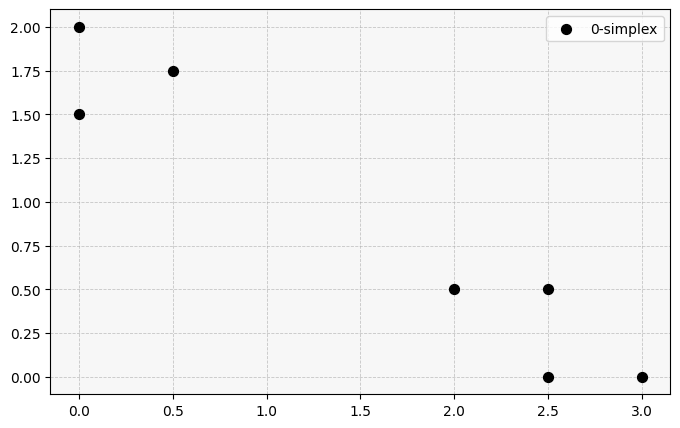

In [45]:
points = np.array([
    [0.0, 2.0],
    [0.0, 1.5],
    [0.5, 1.75],
    [2.0, 0.5],
    [2.5, 0.5],
    [2.5, 0.0],
    [3.0, 0.0]
])
fig, ax = plot_points(points)
ax.legend()
plt.show()


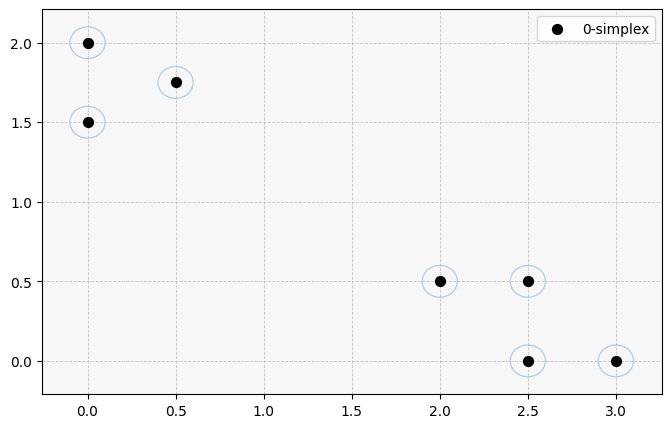

In [46]:
fig, ax = plot_points(points)
add_circles(ax, points, radius=0.1)
ax.legend()
plt.show()


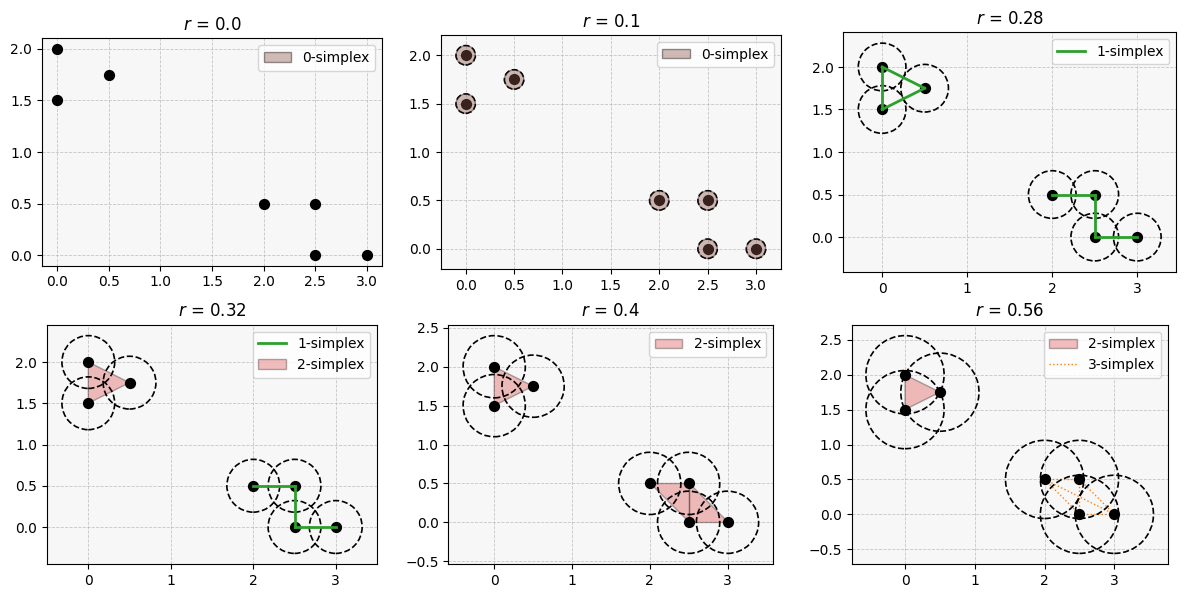

In [47]:
r_vals = [0.0, 0.1, 0.28, 0.32, 0.4, 0.56]
point_color='k'
point_size=50
background_color='#f7f7f7'

fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=False)
axes = axes.flatten()
for idx, r in enumerate(r_vals):
    ax = axes[idx]
    cech = cech_complex(points, r)
    ax.clear()

    ax.scatter(points[:, 0], points[:, 1], c=point_color, s=point_size, zorder=5)
    ax.grid(
        True,
        linestyle='--',
        linewidth=0.6,
        alpha=0.7
    )
    ax.set_facecolor(background_color)
    plot_complex_by_point(fig, ax, points, cech, r)
    ax.set_title(f"$r$ = {r}", fontsize=12)

plt.tight_layout()
plt.show()

Čech Complex Time: 14.3809 seconds


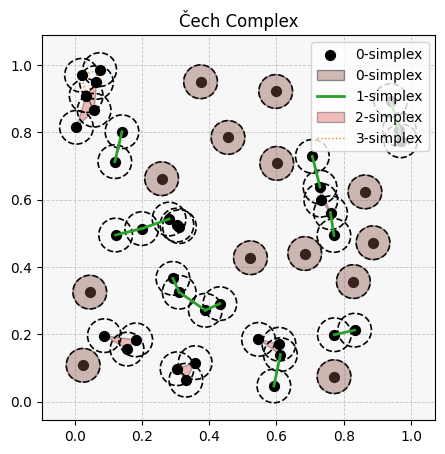

In [48]:
np.random.seed(42)
cloud_points = np.random.rand(50, 2)
r = 0.05

start = time.time()
cech = cech_complex(cloud_points, r)
cech_time = time.time() - start

print(f"Čech Complex Time: {cech_time:.4f} seconds")

fig, ax = plot_points(cloud_points)
plot_complex_by_point(fig, ax, cloud_points, cech, r_circle=r)
plt.title("Čech Complex")
plt.show()

Как видим, даже для 50 синтетических 2-D точек построение Čech-Complex требует значительного времени, хотя мы ограничиваемся лишь 3-симплексом: в этой реализации перебираются все четвёрки точек, $O(n^4)$

В Vietoris–Rips проверку общего пересечения заменим попарными проверками расстояний.

##### Vietoris–Rips Complex

Vietoris–Rips Complex совпадает с Čech-Complex для $0$ и $1$-симплексов. Симплексы более высоких порядков $k$ определяются просто $k+1$-кликами в графе на точках:

$$
X_{k+1} = \{x_0, \ldots x_k\} \in S_k ⇔ \max_{x, y \in X_{k+1}} d(x, y) \leqslant 2r
$$

В результате облако данных $X$ представляется в виде графа с вершинами в сэмплах и ребрами -- 1-симплексами.

<img src="src/H1vuM.png" width="600" style="max-width: 100%; height: auto;">


In [50]:
# ——— Utility: pairwise distance matrix ———
def distance_matrix(points):
    pts = np.asarray(points)
    n = len(pts)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            D[i, j] = D[j, i] = np.linalg.norm(pts[i] - pts[j])
    return D

def rips_complex(points, r):
    D = distance_matrix(points)
    n = len(points)
    edges = [(i,j) for i,j in itertools.combinations(range(n),2) if D[i,j] <= 2*r]
    triangles = [(i,j,k)
                 for i,j,k in itertools.combinations(range(n),3)
                 if D[i,j] <= 2*r and D[i,k] <= 2*r and D[j,k] <= 2*r]
    tetras = [(i,j,k,l)
              for i,j,k,l in itertools.combinations(range(n),4)
              if all(D[a,b] <= 2*r
                     for a,b in itertools.combinations((i,j,k,l),2))]
    return {'edges': edges, 'triangles': triangles, 'tetras': tetras}

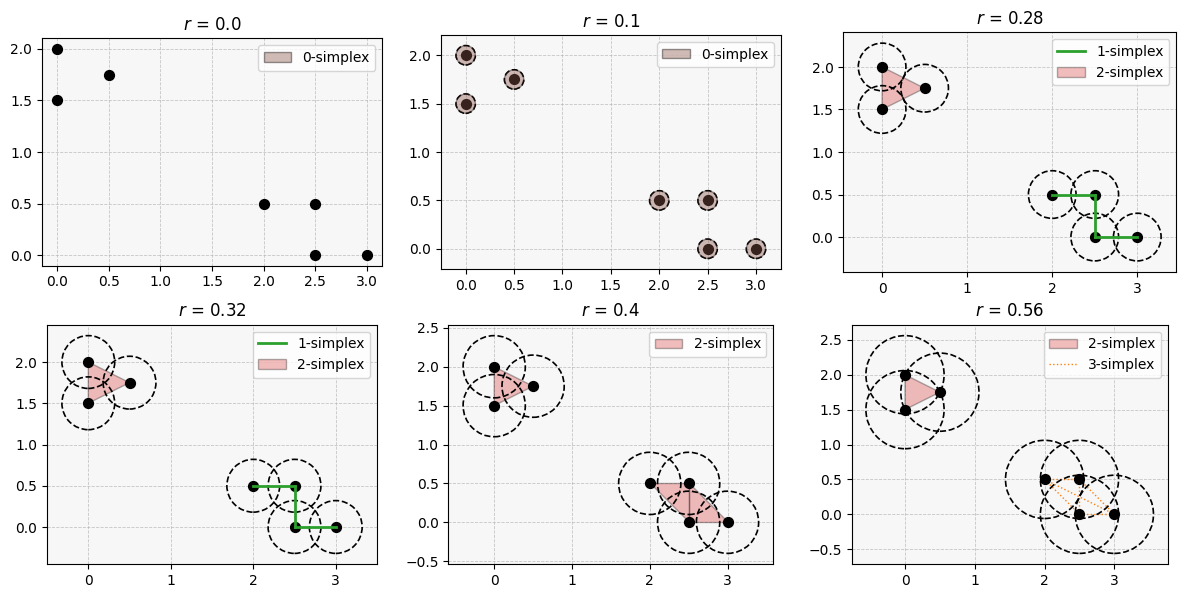

In [51]:
r_vals = [0.0, 0.1, 0.28, 0.32, 0.4, 0.56]
point_color='k'
point_size=50
background_color='#f7f7f7'

fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=False)
axes = axes.flatten()
for idx, r in enumerate(r_vals):
    ax = axes[idx]
    rips = rips_complex(points, r)
    ax.clear()

    ax.scatter(points[:, 0], points[:, 1], c=point_color, s=point_size, zorder=5)
    ax.grid(
        True,
        linestyle='--',
        linewidth=0.6,
        alpha=0.7
    )
    ax.set_facecolor(background_color)
    plot_complex_by_point(fig, ax, points, rips, r)
    ax.set_title(f"$r$ = {r}", fontsize=12)

plt.tight_layout()
plt.show()

Rips Complex Time: 0.1659 seconds


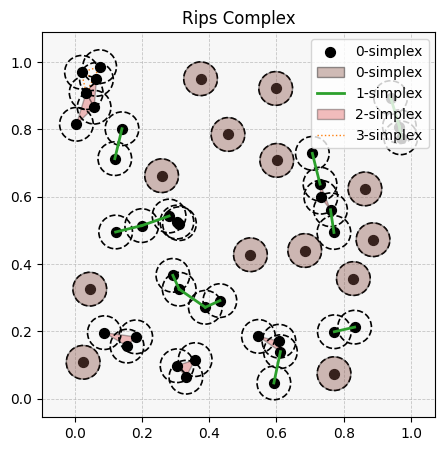

In [52]:
start = time.time()
r = 0.05
rips = rips_complex(cloud_points, r)
rips_time = time.time() - start
print(f"Rips Complex Time: {rips_time:.4f} seconds")

fig, ax = plot_points(cloud_points)
plot_complex_by_point(fig, ax, cloud_points, rips, r_circle=r)
plt.title("Rips Complex")
plt.show()

#### Summary

**Визуализация**

<img src="src/vietoris_rips_point_cloud.gif" width="500" style="max-width: 100%; height: auto;">


### U -- Uniform

In [54]:
Video(filename="src/PoleU.mp4", embed=False, width=640)


В примерах выше мы наблюдали, что у Симплексных комплексов есть 1 важный гиперпараметр -- радиус окружности, который определяет "соседство" примеров.

Его значение задаёт "разрешение" на котором мы описываем многообразие: большой радиус улавливает глобальные закономерности, но теряет в локальных и наоборот.

Как подобрать радиус окружности корректно?

Если данные на многообразие расположены **равномерно**, то одним радиусом мы захватим примерно одинаковое **ожидаемое число соседей** вдали от границы.

Таким образом, в UMAP вводится первый гиперпараметр (`n_neighbors`), вместо радиуса, который является специфичным под каждый датасет и описывает его геометрию/масштаб (вспоминаем DBSCAN).


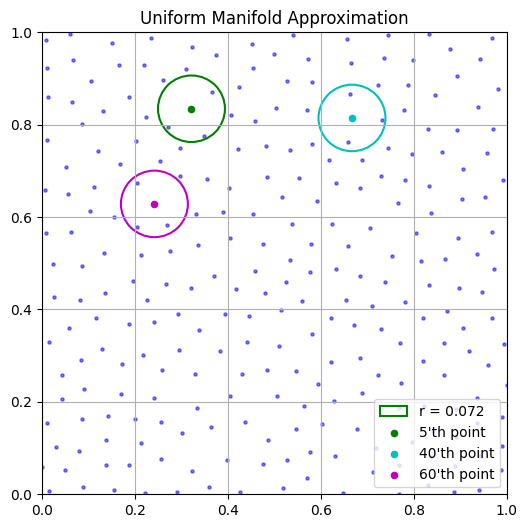

In [55]:
def poisson_disk_sampling(width=1.0, height=1.0, d=0.05, k=30, seed=42):
    """
    Generate points in [0, width] x [0, height] with minimum distance d using Poisson disk sampling.
    """

    rng = np.random.RandomState(seed)

    cell_size = d / np.sqrt(2)
    grid_cols = int(np.ceil(width / cell_size))
    grid_rows = int(np.ceil(height / cell_size))
    grid = -np.ones((grid_rows, grid_cols), dtype=int)  # Grid to store point indices (-1: empty)

    points = []
    active = []

    initial_point = rng.uniform([0, 0], [width, height])
    points.append(initial_point)
    active.append(0)
    row = int(initial_point[1] / cell_size)
    col = int(initial_point[0] / cell_size)
    grid[row, col] = 0

    def is_valid(candidate, points, grid, cell_size, d, width, height):
        row = int(candidate[1] / cell_size)
        col = int(candidate[0] / cell_size)
        if row < 0 or row >= grid.shape[0] or col < 0 or col >= grid.shape[1]:
            return False
        # Check neighboring cells (up to 2 cells away)
        for i in range(max(0, row - 2), min(grid.shape[0], row + 3)):
            for j in range(max(0, col - 2), min(grid.shape[1], col + 3)):
                idx = grid[i, j]
                if idx != -1:
                    dist = np.linalg.norm(candidate - points[idx])
                    if dist < d:
                        return False
        return True

    while active:
        active_idx = rng.choice(active)
        active_point = points[active_idx]
        found = False
        for _ in range(k):
            theta = rng.uniform(0, 2 * np.pi)
            radius = rng.uniform(d, 2 * d)
            candidate = active_point + np.array([radius * np.cos(theta), radius * np.sin(theta)])
            if (0 <= candidate[0] < width) and (0 <= candidate[1] < height):
                if is_valid(candidate, points, grid, cell_size, d, width, height):
                    points.append(candidate)
                    new_idx = len(points) - 1
                    active.append(new_idx)
                    row = int(candidate[1] / cell_size)
                    col = int(candidate[0] / cell_size)
                    grid[row, col] = new_idx
                    found = True
                    break
        if not found:
            active.remove(active_idx)

    return np.array(points)

def approx_plot(points, mode="Uniform", highlight_indices=[5, 40, 60], highlight_colors=['g', 'c', 'm'], r = [0.072, 0.072, 0.072]):
    # Create the plot
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.5, color='blue')
    constant_r = all([r[0] == radius for radius in r])

    # Add circles
    for i, idx in enumerate(highlight_indices):
        if i != 0 and constant_r:
            label = None
        else:
            label = f'r = {r[i]}'
        x, y = points[idx]
        circle = plt.Circle((x, y), r[i], edgecolor=highlight_colors[i], facecolor='none', linewidth=1.5, label=label)
        ax.add_patch(circle)
        if constant_r:
            label = f'{idx}\'th point'
        else:
            label = None
        ax.scatter(x, y, s=20, alpha=1, color=highlight_colors[i], label=label)

    ax.set_title(f'{mode} Manifold Approximation')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True)
    plt.legend(loc='lower right')
    plt.show()


d = 0.05
poisson_points = poisson_disk_sampling(d=d)
approx_plot(poisson_points)

Однако реальные данные, конечно же, не располагаются равномерно.

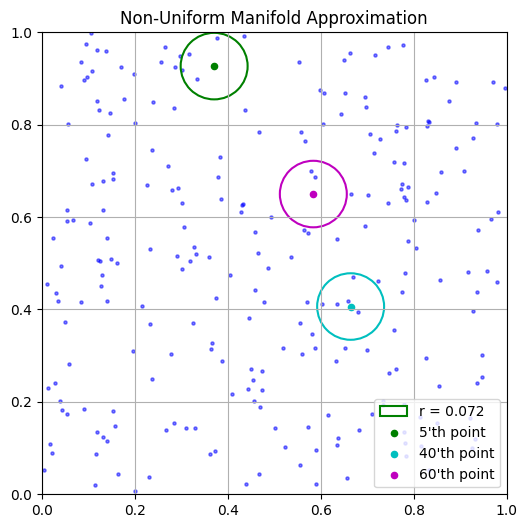

In [56]:
n_points = 250
seed = 42
rng = np.random.default_rng(seed)
non_uniform_points = rng.random((n_points, 2))
approx_plot(non_uniform_points, mode="Non-Uniform")


Как это решить?

### A -- Approximation

In [57]:
Video(filename="src/PoleA.mp4", embed=False, width=640)


<img src="src/lemma1.PNG" width="800" style="max-width: 100%; height: auto;">


<img src="src/7-selective-stretching.png" width="800" style="max-width: 100%; height: auto;">


Мы можем добиться такой аппроксимации, "адаптируя" геометрию датасета под каждую из рассматриваемых точек.

Давайте для каждой точки выбирать радиус, соответствующий её $k$ соседям

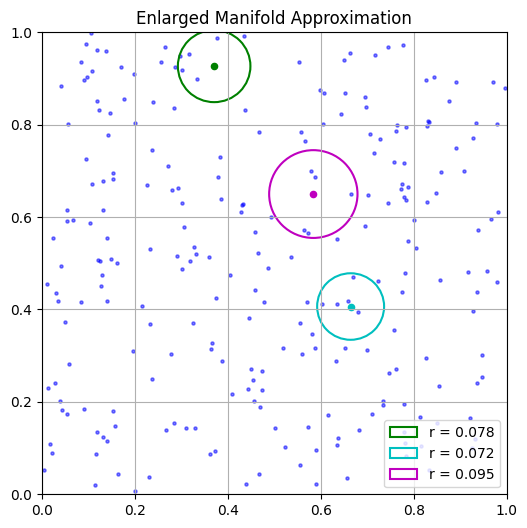

In [60]:
approx_plot(non_uniform_points, mode="Enlarged", r=[0.078, 0.072, 0.095])

Подбирая специфичный радиус $r_i$ под каждую точку $x_i$, вместо одного покрытия $C_r$ мы получаем множество $\{C_{r_i}\}_{i=1}^N$.

Чтобы специфицировать "геометрию" многообразия под каждую из точек $x_i$, нам нужно определить, как взаимосвязаны покрытия $\{C_{r_i}\}$.

Как мы упоминали, Vietoris–Rips покрытие позволяет представить его в виде графа: ребра являются 1-симплексами.

Тогда, чтобы установить взаимосвязь между графами, которая бы отражала геометрию многообразия, давайте сделаем эти рёбра **взвешенными**. Если для точки $x_i$ ближайшей является $x_j$, из этого не следует, что $x_i = \arg\min_{x\in X}d(x, x_j) ⇒$ граф является еще и  **ориентированным**

##### Как определить веса в ребрах графа?

Можно определить в соответствии с расстоянием до соседа.  Однако в таком случае мы столкнёмся с последствиями "проклятия размерности" на реальных примерах

* Для независимых стандартизованных координат $d(x_i,x_j)^2$ имеет порядок $d$, а $d(x_i,x_j)$ — $\sqrt d$. Чем больше размерность, тем больше расстояние даже до ближайшего соседа. При этом разница между ближайшим и 2-м соседом будет незначительная.
* Поэтому используем локальные масштабы расстояний.



Для этого вводят **local connectivity constraint**.

Пусть $X_i$ содержит $k$ соседей $X_{i_1}, \ldots X_{i_k}$. Сначала выбираем $k$ соседей. $\rho_i$ — расстояние до ближайшего соседа с ненулевым расстоянием. Тогда

$$
\rho(X_i, X_{i_p}) = \exp\left\{-\dfrac{\max[0, d(X_i, X_{i_p}) - \rho_i]}{\sigma_i} \right\}.
$$

Это простое экспоненциальное убывание, где ближайшему соседу назначается единичный вес.

Масштаб $\sigma_i$ подбирается из условия на сумму весов
$$
\sum_{p=1}^k \rho(X_i, X_{i_p}) = \log_2k
$$

In [61]:
def _k_nearest_neighbors(points, center_idx, k):
    center = points[center_idx]
    diffs = points - center[None, :]
    dists = np.linalg.norm(diffs, axis=1)
    dists[center_idx] = np.inf
    nn_idx = np.argsort(dists)[:k]
    return nn_idx, dists[nn_idx]

def _solve_sigma_for_target(distances, rho_i, target_sum, tol=1e-6, max_iter=60):
    numerators = np.maximum(0.0, distances - rho_i)
    k = len(distances)
    if np.allclose(numerators, 0.0):
        return float('inf'), float(k)
    min_possible = float(np.sum(numerators == 0.0))
    max_possible = float(k)
    if target_sum <= min_possible:
        return 1e-12, min_possible
    if target_sum >= max_possible:
        return float('inf'), max_possible
    low, high = 1e-12, 1e6
    for _ in range(max_iter):
        mid = (low + high) / 2.0
        vals = np.exp(- numerators / mid)
        s = float(vals.sum())
        if abs(s - target_sum) <= tol:
            return mid, s
        if s > target_sum:
            high = mid
        else:
            low = mid
    mid = (low + high) / 2.0
    vals = np.exp(- numerators / mid)
    return mid, float(vals.sum())

def _negative_exp_weights(distances, rho_i, target_sum=None, desired_max_ratio=None):
    numerators = np.maximum(0.0, distances - rho_i)
    if np.allclose(numerators, 0.0):
        return float('inf'), np.ones_like(distances)
    max_num = numerators.max()
    if target_sum is not None and desired_max_ratio is None:
        sigma, _ = _solve_sigma_for_target(distances, rho_i, target_sum)
        raw = np.exp(- numerators / sigma) if not math.isinf(sigma) else np.ones_like(distances)
        return sigma, raw
    if desired_max_ratio is not None and desired_max_ratio > 1.0 and max_num > 0.0:
        sigma = max_num / math.log(desired_max_ratio)
        raw = np.exp(- numerators / sigma)
        return sigma, raw
    sigma = 1.0
    raw = np.exp(- numerators / sigma)
    return sigma, raw

def approx_neighbors_plot(points,
                          highlight_indices=[5, 40, 60],
                          highlight_colors=['g', 'c', 'm'],
                          k=8,
                          epsilon_pad=0.05,
                          figsize=(10, 6),
                          mode="Negative-exp",
                          target_sum=None,
                          desired_max_ratio=None):

    assert len(highlight_indices) == len(highlight_colors)
    n_centers = len(highlight_indices)

    fig, axes = plt.subplots(nrows=2, ncols=n_centers, figsize=figsize)
    if n_centers == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for col, (center_idx, color) in enumerate(zip(highlight_indices, highlight_colors)):
        ax_orig = axes[0, col]
        ax_rew = axes[1, col]

        nn_idx, dists = _k_nearest_neighbors(points, center_idx, k)
        center = points[center_idx].astype(float)
        neigh = points[nn_idx].astype(float)

        rho_i = float(np.min(dists[dists > 0]))
        targ = target_sum if target_sum is not None else math.log2(k)

        sigma, raw = _negative_exp_weights(
            dists, rho_i,
            target_sum=(targ if desired_max_ratio is None else None),
            desired_max_ratio=desired_max_ratio
        )

        weights = raw

        ax = ax_orig
        ax.scatter(points[:, 0], points[:, 1], s=6, alpha=0.25, color='lightgray')
        ax.scatter(neigh[:, 0], neigh[:, 1], s=30, alpha=0.95, color='tab:blue')
        ax.scatter([center[0]], [center[1]], s=80, color=color, edgecolor='k', zorder=5)
        for j, ni in enumerate(nn_idx):
            npt = points[ni]
            ax.plot([center[0], npt[0]], [center[1], npt[1]],
                    linewidth=1.0, alpha=0.8, color=color)
            midx = 0.5 * (center[0] + npt[0]); midy = 0.5 * (center[1] + npt[1])
            ax.text(midx, midy, f"{dists[j]:.3f}", fontsize=8,
                    ha='center', va='center',
                    bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.0))

        all_x = np.concatenate(([center[0]], neigh[:, 0]))
        all_y = np.concatenate(([center[1]], neigh[:, 1]))
        dx = max(all_x.max() - all_x.min(), 1e-4)
        dy = max(all_y.max() - all_y.min(), 1e-4)
        ax.set_xlim(all_x.min() - epsilon_pad * dx, all_x.max() + epsilon_pad * dx)
        ax.set_ylim(all_y.min() - epsilon_pad * dy, all_y.max() + epsilon_pad * dy)
        ax.set_title(f"Original Graph")
        ax.grid(True)

        ax = ax_rew
        ax.scatter(points[:, 0], points[:, 1], s=6, alpha=0.25, color='lightgray')
        ax.scatter(neigh[:, 0], neigh[:, 1], s=30, alpha=0.95, color='tab:blue')
        ax.scatter([center[0]], [center[1]], s=80, color=color, edgecolor='k', zorder=5)
        for j, ni in enumerate(nn_idx):
            npt = points[ni]
            ax.plot([center[0], npt[0]], [center[1], npt[1]],
                    linewidth=1.0, alpha=0.9, color=color)
            midx = 0.5 * (center[0] + npt[0]); midy = 0.5 * (center[1] + npt[1])
            ax.text(midx, midy, f"{weights[j]:.3f}", fontsize=8,
                    ha='center', va='center',
                    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1.0))

        all_x = np.concatenate(([center[0]], neigh[:, 0]))
        all_y = np.concatenate(([center[1]], neigh[:, 1]))
        dx = max(all_x.max() - all_x.min(), 1e-4)
        dy = max(all_y.max() - all_y.min(), 1e-4)
        ax.set_xlim(all_x.min() - epsilon_pad * dx, all_x.max() + epsilon_pad * dx)
        ax.set_ylim(all_y.min() - epsilon_pad * dy, all_y.max() + epsilon_pad * dy)
        ax.set_title(
            f"Local Connect. Graph σ={'inf' if math.isinf(sigma) else f'{sigma:.2g}'}"
        )
        ax.grid(True)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

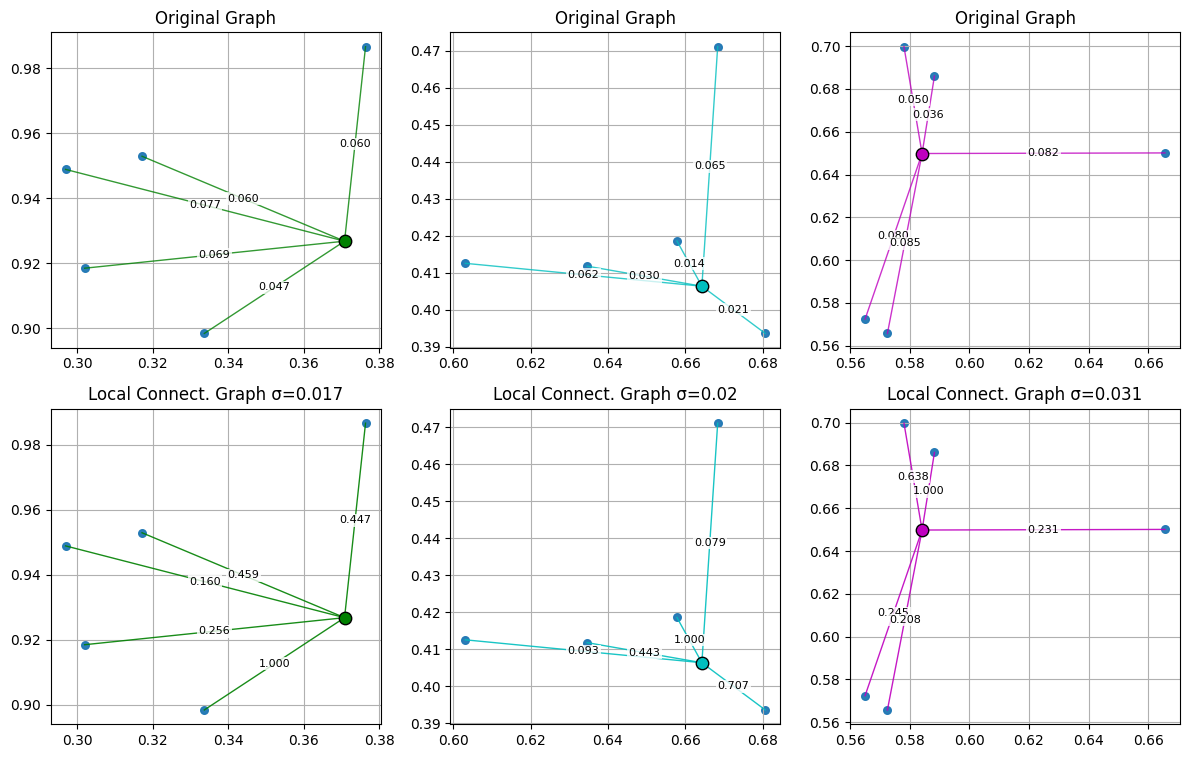

In [62]:
approx_neighbors_plot(non_uniform_points, k=5, figsize=(12, 8))

Таким образом для точки $X_i$ мы можем построить ориентированный взвешенный граф, который подходящим образом описывает структуру датасета относительно неё.

Далее имеем $N$ таких графов

##### Как объединить графы?

<img src="src/theorem1.PNG" width="800" style="max-width: 100%; height: auto;">


<img src="src/fuzzy_simplicial_complex.png" width="800" style="max-width: 100%; height: auto;">


На практике графы объединяют нечётким объединением.

Из построения следует, что $x_i$ и $x_j$ могут быть связаны ребром только в покрытиях $C_{r_i}$ и $C_{r_j}$ (но необязательно в обоих). В результате процедура объединения сводится к получению из *ориентированных* графов *неориентированного*.

Для этого веса графов можно интерпретировать как вероятности. Тогда неориентированное ребро -- это вероятность "объединить" ориентированные рёбра, по аналогии с вероятностью объединения независимых событий

$$
P(x_i - x_j) = P(\{x_i \rightarrow x_j \} \cup \{x_j \rightarrow x_i\}) = P(\{x_i \rightarrow x_j \}) + P(\{x_j \rightarrow x_i \}) - P(\{x_i \rightarrow x_j \})P(\{x_j \rightarrow x_i \}).
$$

В примере выше:
* $P(x_1 - x_2) = 1.0$;
* $P(x_1 - x_3) = 0.4 + 0.0 - 0 = 0.4$;
* $P(x_2 - x_3) = 1.0 + 0.9 - 0.9 = 1.0$.

<img src="src/graph_construction_pipeline.png" width="800" style="max-width: 100%; height: auto;">


### P - Projection

In [66]:
Video(filename="src/PoleP.mp4", embed=False, width=640)


Отобразить полученный высокоразмерный граф в низкоразмерное представление гораздо понятнее :)

<img src="src/graph_comparison.PNG" width="800" style="max-width: 100%; height: auto;">


* Чем более "похожие" графы, тем лучше проецирование.
* В общем случае сравнение графов -- нетривиальная задача.
* Но у нас есть одна сильная особенность, которая всё упрощает: узлы должны повторяться, тк они соответствуют конкретным примерам.
* В результате критерием расположения вершин графа является схожесть их рёбер.
* Или, что тоже самое, близость матриц смежности.
* Поскольку ребра в high-dimensional графе представляют вероятности, можно напрямую оптимизировать бинарной кросс энтропией:
$$
\sum_{e\in E}\left[ w_h(e)\log\dfrac{w_h(e)}{w_l(e)} + (1 - w_h(e)) \log\dfrac{(1 - w_h(e))}{(1 - w_l(e))}\right],
$$
где $E=\{\{i,j\}:1\leq i<j\leq n\}$ — все неупорядоченные пары различных объектов, $n$ — число объектов.

С деталями инициализации графа и регуляризацией на координаты $y_1$, $y_2$ можно ознакомиться в статье.



### Weaknesses

Как и всякие основополагающие работы, UMAP не лишены скромности в обсуждении своих слабостей

* Как и всякие нелинейные методы понижения размерности (t-SNE, Isomap), у UMAP нет такой интерпретируемости, как у PCA и подобных матричных разложений. Это может быть критичным в анализе данных
* UMAP аппроксимирует аппроксимацию многообразия :) UMAP предполагает наличие многообразия у данных $X$, таким образом предполагает, что $X$ хорошо описывает $\mathcal{M}$, чтобы полученное приближение $Y$ также хорошо его описывало.
* UMAP как и t-SNE нацелен на локальную структуру данных, поскольку закладывает что близкие расстояния более важные, чем дальние.
* UMAP может искажать локальную плотность данных. Если структура критически важна, это может негативно сказаться на финальной аппроксимации



### UMAP Examples

#### MNIST

In [68]:
n_clusters = 10  # Since MNIST has 10 digits (0-9)
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans.fit(X_umap_train)

cluster_to_label = map_clusters_to_labels(labels_mnist_train, kmeans.labels_, n_clusters)

umap_clusters = kmeans.labels_
y_pred_test = np.array([cluster_to_label[cluster] for cluster in umap_clusters])

print("\nUMAP + K-means")
print(classification_report(labels_mnist_train, y_pred_test, zero_division=0))



UMAP + K-means
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      6903
           1       0.96      0.99      0.98      7877
           2       0.98      0.96      0.97      6990
           3       0.54      0.97      0.69      7141
           4       0.98      0.95      0.97      6824
           5       0.00      0.00      0.00      6313
           6       0.98      0.99      0.98      6876
           7       0.91      0.97      0.94      7293
           8       0.91      0.93      0.92      6825
           9       0.93      0.90      0.92      6958

    accuracy                           0.88     70000
   macro avg       0.82      0.87      0.84     70000
weighted avg       0.83      0.88      0.84     70000



In [69]:
%%time
ri_score = rand_score(labels_mnist_train, umap_clusters)
ari_score = adjusted_rand_score(labels_mnist_train, umap_clusters)
print(f"Rand Index (RI): {ri_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")


Rand Index (RI): 0.9609
Adjusted Rand Index (ARI): 0.7930
CPU times: user 6.68 ms, sys: 3.96 ms, total: 10.6 ms
Wall time: 10 ms


In [70]:
%%time
silhouette_avg = silhouette_score(X_umap_train, umap_clusters)
db_avg = davies_bouldin_score(X_umap_train, umap_clusters)

print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies Bouldin Score: {db_avg:.4f}")


Silhouette Score: 0.6057
Davies Bouldin Score: 0.5732
CPU times: user 28.1 s, sys: 6.06 s, total: 34.1 s
Wall time: 34.1 s


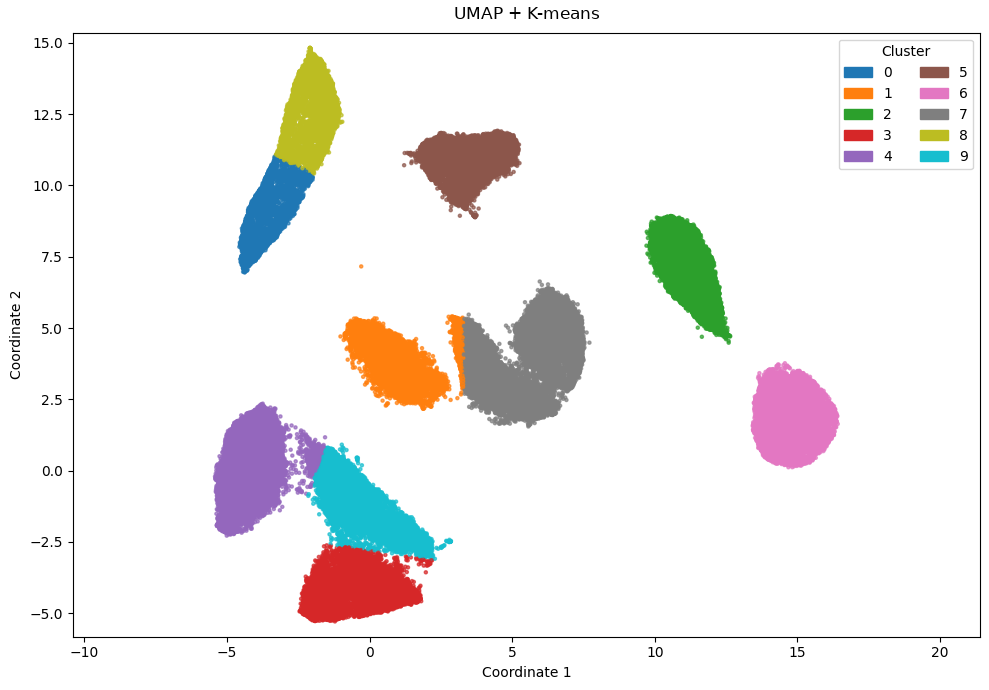

In [71]:
plot_mnist_embedding(X_umap_train, umap_clusters, "UMAP + K-means", label_name="Cluster")


#### PCA, t-SNE и UMAP: одна выборка

Обучение K-means и расчёт метрик — на одной и той же выборке MNIST.


In [72]:
for name, embedding in [
    ("PCA", X_pca_mnist), ("t-SNE", tsne_X), ("UMAP", X_umap_train),
]:
    clusters = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(embedding)
    mapping = map_clusters_to_labels(y, clusters, 10)
    predicted = np.array([mapping[cluster] for cluster in clusters])
    print(f"{name}:")
    print(f"Accuracy: {np.mean(predicted == y):.4f}")
    print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(y, clusters):.4f}")
    print(f"Silhouette Score: {silhouette_score(embedding, clusters):.4f}")
    print(f"Davies Bouldin Score: {davies_bouldin_score(embedding, clusters):.4f}")
    print()


PCA:
Accuracy: 0.4034
Adjusted Rand Index (ARI): 0.2342
Silhouette Score: 0.3512
Davies Bouldin Score: 0.8415

t-SNE:
Accuracy: 0.9159
Adjusted Rand Index (ARI): 0.8309
Silhouette Score: 0.4441
Davies Bouldin Score: 0.7458

UMAP:
Accuracy: 0.8763
Adjusted Rand Index (ARI): 0.7930
Silhouette Score: 0.6057
Davies Bouldin Score: 0.5732



In [73]:
print(f"PCA (2D) fit_transform: {pca_seconds:.3f} s")
print(f"t-SNE fit_transform: {tsne_seconds:.3f} s ({tsne_seconds / 60:.2f} min)")
print(f"UMAP fit_transform: {umap_seconds:.3f} s ({umap_seconds / 60:.2f} min)")
print(f"t-SNE / UMAP: {tsne_seconds / umap_seconds:.2f}x")


PCA (2D) fit_transform: 0.569 s
t-SNE fit_transform: 728.118 s (12.14 min)
UMAP fit_transform: 55.747 s (0.93 min)
t-SNE / UMAP: 13.06x


#### Integer visualization

Source -- https://johnhw.github.io/umap_primes/index.md.html, https://github.com/BielStela/prime_factors/blob/master/prime_factors.ipynb

Число -- это число)

Т.е. $x \in \mathbb{R}^1$. Как тогда представлять числа высокоразмерными данными?

Разложение на простые множители!

Памяти колаба не хватает для построения графа, поэтому посмотрим на финальный результат

<img src="src/primes_umap_1e6_contrast_enhanced.png" width="717" style="max-width: 100%; height: auto;">
